In [ ]:
from google.colab import files

uploaded = files.upload()

Saving archive (1).zip to archive (1).zip


In [ ]:
import zipfile
import os

zip_file = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall('/content/heart_dataset')

print("Dataset extracted successfully!")

os.listdir('/content/heart_dataset')

Dataset extracted successfully!


['heart_disease.csv']

In [ ]:
for root, dirs, files_list in os.walk('/content/heart_dataset'):
    for file in files_list:
        if file.endswith('.csv'):
            print(os.path.join(root, file))

/content/heart_dataset/heart_disease.csv


In [ ]:
import pandas as pd

df = pd.read_csv('/content/heart_dataset/heart_disease.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
df.head()

,Age,Gender,Blood Pressure,Cholesterol Level,Exercise Habits,Smoking,Family Heart Disease,Diabetes,BMI,High Blood Pressure,...,High LDL Cholesterol,Alcohol Consumption,Stress Level,Sleep Hours,Sugar Consumption,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Heart Disease Status
0,56.0,Male,153.0,155.0,High,Yes,Yes,No,24.991591,Yes,...,No,High,Medium,7.633228,Medium,342.0,NaN,12.969246,12.387250,No
1,69.0,Female,146.0,286.0,High,No,Yes,Yes,25.221799,No,...,No,Medium,High,8.744034,Medium,133.0,157.0,9.355389,19.298875,No
2,46.0,Male,126.0,216.0,Low,No,No,No,29.855447,No,...,Yes,Low,Low,4.440440,Low,393.0,92.0,12.709873,11.230926,No
3,32.0,Female,122.0,293.0,High,Yes,Yes,No,24.130477,Yes,...,Yes,Low,High,5.249405,High,293.0,94.0,12.509046,5.961958,No
4,60.0,Male,166.0,242.0,Low,Yes,Yes,Yes,20.486289,Yes,...,No,Low,High,7.030971,High,263.0,154.0,10.381259,8.153887,No


In [ ]:
print("Rows and Columns:", df.shape)

Rows and Columns: (10000, 21)


In [ ]:
print(df.columns.tolist())

['Age', 'Gender', 'Blood Pressure', 'Cholesterol Level', 'Exercise Habits', 'Smoking', 'Family Heart Disease', 'Diabetes', 'BMI', 'High Blood Pressure', 'Low HDL Cholesterol', 'High LDL Cholesterol', 'Alcohol Consumption', 'Stress Level', 'Sleep Hours', 'Sugar Consumption', 'Triglyceride Level', 'Fasting Blood Sugar', 'CRP Level', 'Homocysteine Level', 'Heart Disease Status']


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Age                   9971 non-null   float64
 1   Gender                9981 non-null   object 
 2   Blood Pressure        9981 non-null   float64
 3   Cholesterol Level     9970 non-null   float64
 4   Exercise Habits       9975 non-null   object 
 5   Smoking               9975 non-null   object 
 6   Family Heart Disease  9979 non-null   object 
 7   Diabetes              9970 non-null   object 
 8   BMI                   9978 non-null   float64
 9   High Blood Pressure   9974 non-null   object 
 10  Low HDL Cholesterol   9975 non-null   object 
 11  High LDL Cholesterol  9974 non-null   object 
 12  Alcohol Consumption   7414 non-null   object 
 13  Stress Level          9978 non-null   object 
 14  Sleep Hours           9975 non-null   float64
 15  Sugar Consumption   

In [ ]:
df.isnull().sum()

,0
Age,29
Gender,19
Blood Pressure,19
Cholesterol Level,30
Exercise Habits,25
Smoking,25
Family Heart Disease,21
Diabetes,30
BMI,22
High Blood Pressure,26


In [ ]:
df.describe()

,Age,Blood Pressure,Cholesterol Level,BMI,Sleep Hours,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level
count,9971.000000,9981.000000,9970.000000,9978.000000,9975.000000,9974.000000,9978.000000,9974.000000,9980.000000
mean,49.296259,149.757740,225.425577,29.077269,6.991329,250.734409,120.142213,7.472201,12.456271
std,18.193970,17.572969,43.575809,6.307098,1.753195,87.067226,23.584011,4.340248,4.323426
min,18.000000,120.000000,150.000000,18.002837,4.000605,100.000000,80.000000,0.003647,5.000236
25%,34.000000,134.000000,187.000000,23.658075,5.449866,176.000000,99.000000,3.674126,8.723334
50%,49.000000,150.000000,226.000000,29.079492,7.003252,250.000000,120.000000,7.472164,12.409395
75%,65.000000,165.000000,263.000000,34.520015,8.531577,326.000000,141.000000,11.255592,16.140564
max,80.000000,180.000000,300.000000,39.996954,9.999952,400.000000,160.000000,14.997087,19.999037


In [ ]:
print(df['Heart Disease Status'].value_counts())

Heart Disease Status
No     8000
Yes    2000
Name: count, dtype: int64


In [ ]:
print(
    df['Heart Disease Status'].value_counts(normalize=True) * 100
)

Heart Disease Status
No     80.0
Yes    20.0
Name: proportion, dtype: float64


In [ ]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


In [ ]:
missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

print(missing_percentage.sort_values(ascending=False))

Alcohol Consumption     25.86
Diabetes                 0.30
Sugar Consumption        0.30
Cholesterol Level        0.30
Age                      0.29
Triglyceride Level       0.26
CRP Level                0.26
High LDL Cholesterol     0.26
High Blood Pressure      0.26
Low HDL Cholesterol      0.25
Sleep Hours              0.25
Exercise Habits          0.25
Smoking                  0.25
Fasting Blood Sugar      0.22
BMI                      0.22
Stress Level             0.22
Family Heart Disease     0.21
Homocysteine Level       0.20
Blood Pressure           0.19
Gender                   0.19
Heart Disease Status     0.00
dtype: float64


In [ ]:
for column in df.columns:
    print("\nColumn:", column)
    print(df[column].unique()[:10])


Column: Age
[56. 69. 46. 32. 60. 25. 78. 38. 75. 36.]

Column: Gender
['Male' 'Female' nan]

Column: Blood Pressure
[153. 146. 126. 122. 166. 152. 121. 161. 135. 144.]

Column: Cholesterol Level
[155. 286. 216. 293. 242. 257. 175. 187. 291. 252.]

Column: Exercise Habits
['High' 'Low' 'Medium' nan]

Column: Smoking
['Yes' 'No' nan]

Column: Family Heart Disease
['Yes' 'No' nan]

Column: Diabetes
['No' 'Yes' nan]

Column: BMI
[24.99159109 25.22179852 29.85544714 24.13047688 20.48628889 28.14468146
 18.04233189 34.73668257 34.49311222 30.1421494 ]

Column: High Blood Pressure
['Yes' 'No' nan]

Column: Low HDL Cholesterol
['Yes' 'No' nan]

Column: High LDL Cholesterol
['No' 'Yes' nan]

Column: Alcohol Consumption
['High' 'Medium' 'Low' nan]

Column: Stress Level
['Medium' 'High' 'Low' nan]

Column: Sleep Hours
[7.63322838 8.74403397 4.44044012 5.2494047  7.03097143 5.50487565
 9.24091119 7.84100783 6.94140285 4.0026617 ]

Column: Sugar Consumption
['Medium' 'Low' 'High' nan]

Column: Tri

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

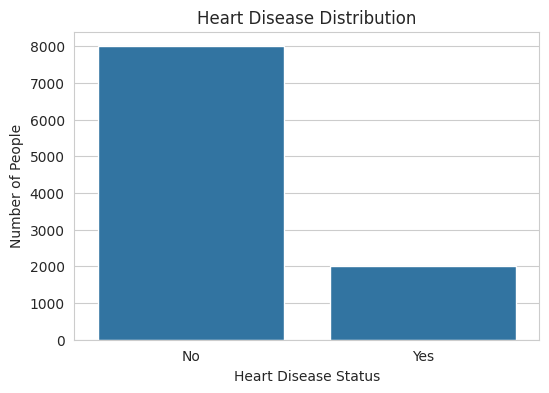

In [ ]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x='Heart Disease Status'
)

plt.title("Heart Disease Distribution")
plt.xlabel("Heart Disease Status")
plt.ylabel("Number of People")

plt.show()

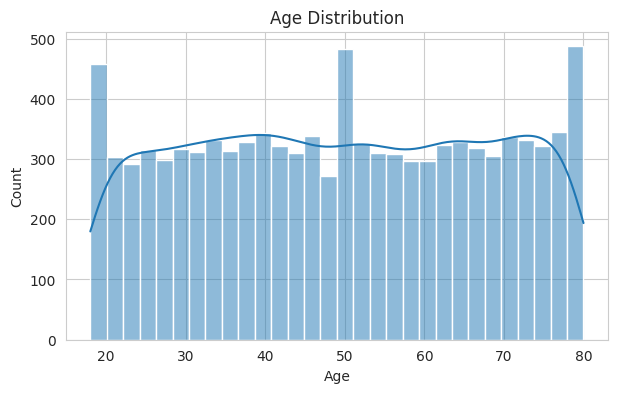

In [ ]:
plt.figure(figsize=(7, 4))

sns.histplot(
    data=df,
    x='Age',
    bins=30,
    kde=True
)

plt.title("Age Distribution")
plt.show()

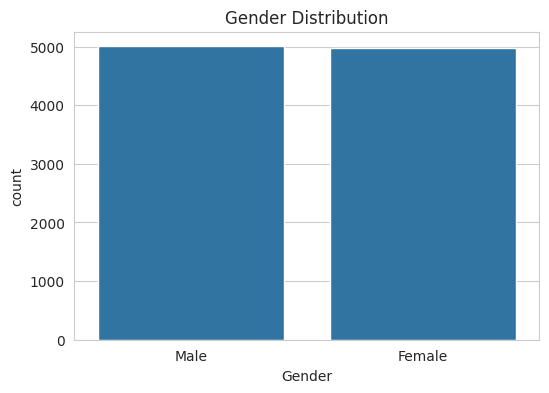

In [ ]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x='Gender'
)

plt.title("Gender Distribution")
plt.show()

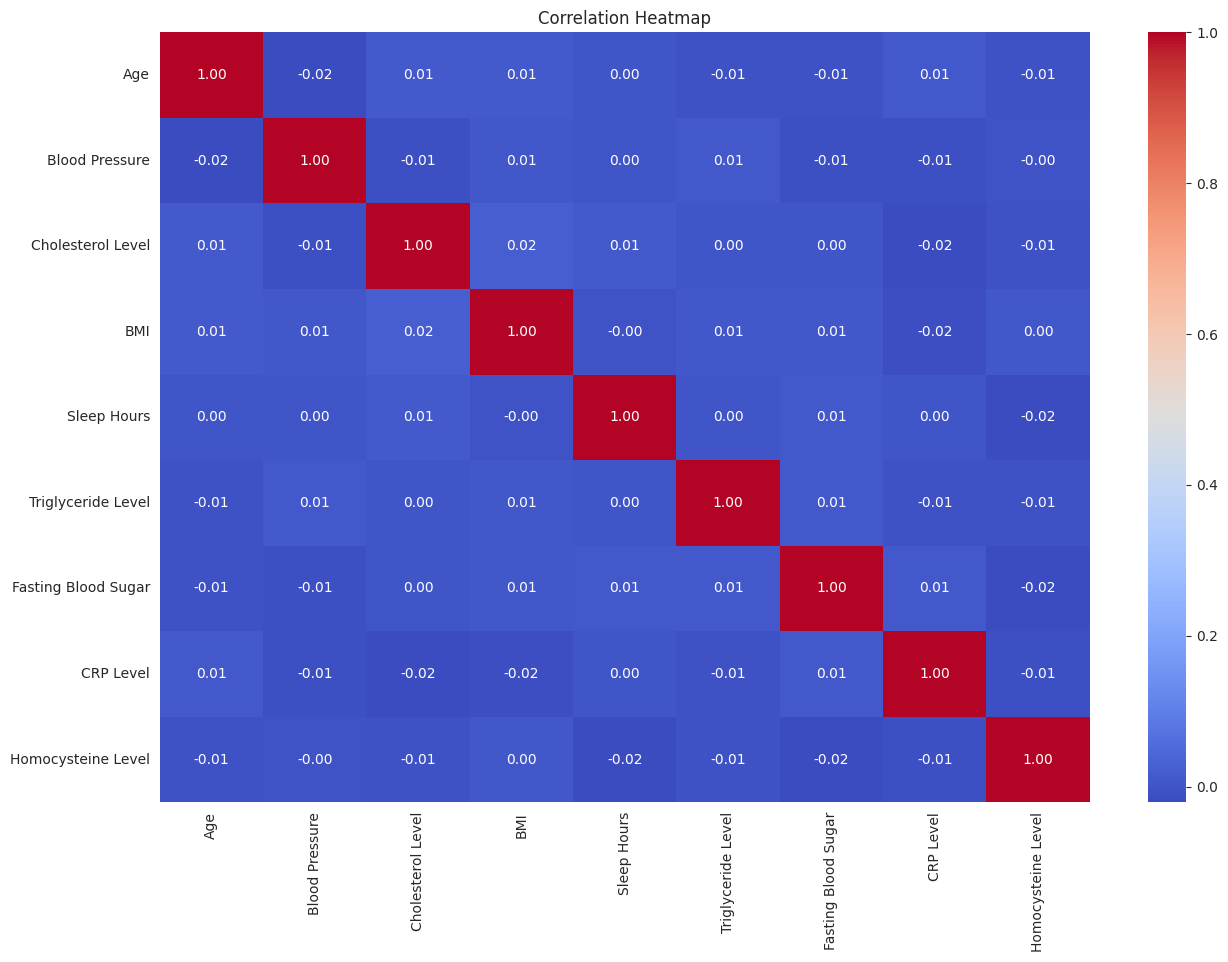

In [ ]:
plt.figure(figsize=(15, 10))

numeric_df = df.select_dtypes(include='number')

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()

In [ ]:
print("Dataset Shape:", df.shape)

print("\nDuplicate Records:", df.duplicated().sum())

print("\nTarget Distribution:")
print(df['Heart Disease Status'].value_counts())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (10000, 21)

Duplicate Records: 0

Target Distribution:
Heart Disease Status
No     8000
Yes    2000
Name: count, dtype: int64

Missing Values:
Age                       29
Gender                    19
Blood Pressure            19
Cholesterol Level         30
Exercise Habits           25
Smoking                   25
Family Heart Disease      21
Diabetes                  30
BMI                       22
High Blood Pressure       26
Low HDL Cholesterol       25
High LDL Cholesterol      26
Alcohol Consumption     2586
Stress Level              22
Sleep Hours               25
Sugar Consumption         30
Triglyceride Level        26
Fasting Blood Sugar       22
CRP Level                 26
Homocysteine Level        20
Heart Disease Status       0
dtype: int64


In [ ]:
df.isnull().sum().sort_values(ascending=False)

,0
Alcohol Consumption,2586
Diabetes,30
Sugar Consumption,30
Cholesterol Level,30
Age,29
Triglyceride Level,26
CRP Level,26
High LDL Cholesterol,26
High Blood Pressure,26
Low HDL Cholesterol,25


In [ ]:
print(df.dtypes)

Age                     float64
Gender                   object
Blood Pressure          float64
Cholesterol Level       float64
Exercise Habits          object
Smoking                  object
Family Heart Disease     object
Diabetes                 object
BMI                     float64
High Blood Pressure      object
Low HDL Cholesterol      object
High LDL Cholesterol     object
Alcohol Consumption      object
Stress Level             object
Sleep Hours             float64
Sugar Consumption        object
Triglyceride Level      float64
Fasting Blood Sugar     float64
CRP Level               float64
Homocysteine Level      float64
Heart Disease Status     object
dtype: object


In [ ]:
print("Alcohol Consumption:")
print(df['Alcohol Consumption'].value_counts(dropna=False))

print("\nUnique Alcohol Values:")
print(df['Alcohol Consumption'].unique())

Alcohol Consumption:
Alcohol Consumption
NaN       2586
Medium    2500
Low       2488
High      2426
Name: count, dtype: int64

Unique Alcohol Values:
['High' 'Medium' 'Low' nan]


In [ ]:
print("Heart Disease Distribution:")

print(df['Heart Disease Status'].value_counts())

print("\nPercentage Distribution:")

print(
    df['Heart Disease Status']
    .value_counts(normalize=True) * 100
)

Heart Disease Distribution:
Heart Disease Status
No     8000
Yes    2000
Name: count, dtype: int64

Percentage Distribution:
Heart Disease Status
No     80.0
Yes    20.0
Name: proportion, dtype: float64


In [ ]:
categorical_columns = df.select_dtypes(
    include='object'
).columns

for col in categorical_columns:

    print("\nColumn:", col)

    print(df[col].value_counts(dropna=False))


Column: Gender
Gender
Male      5003
Female    4978
NaN         19
Name: count, dtype: int64

Column: Exercise Habits
Exercise Habits
High      3372
Medium    3332
Low       3271
NaN         25
Name: count, dtype: int64

Column: Smoking
Smoking
Yes    5123
No     4852
NaN      25
Name: count, dtype: int64

Column: Family Heart Disease
Family Heart Disease
No     5004
Yes    4975
NaN      21
Name: count, dtype: int64

Column: Diabetes
Diabetes
No     5018
Yes    4952
NaN      30
Name: count, dtype: int64

Column: High Blood Pressure
High Blood Pressure
Yes    5022
No     4952
NaN      26
Name: count, dtype: int64

Column: Low HDL Cholesterol
Low HDL Cholesterol
Yes    5000
No     4975
NaN      25
Name: count, dtype: int64

Column: High LDL Cholesterol
High LDL Cholesterol
No     5036
Yes    4938
NaN      26
Name: count, dtype: int64

Column: Alcohol Consumption
Alcohol Consumption
NaN       2586
Medium    2500
Low       2488
High      2426
Name: count, dtype: int64

Column: Stress Leve

In [ ]:
# Check duplicate records

duplicates = df.duplicated().sum()

print("Total duplicate rows:", duplicates)

NameError: name 'df' is not defined

In [ ]:
import pandas as pd
import os
import zipfile

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving archive (1).zip to archive (1) (1).zip


In [ ]:
zip_file = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall('/content/heart_dataset')

In [ ]:
df = pd.read_csv(
    '/content/heart_dataset/heart_disease.csv'
)

print("Dataset loaded successfully!")
print(df.shape)

Dataset loaded successfully!
(10000, 21)


In [ ]:
duplicates = df.duplicated().sum()

print("Total duplicate rows:", duplicates)

Total duplicate rows: 0


In [ ]:
missing_summary = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': df.isnull().mean() * 100
})

missing_summary = missing_summary.sort_values(
    by='Missing Percentage',
    ascending=False
)

print(missing_summary)

                      Missing Values  Missing Percentage
Alcohol Consumption             2586               25.86
Diabetes                          30                0.30
Sugar Consumption                 30                0.30
Cholesterol Level                 30                0.30
Age                               29                0.29
Triglyceride Level                26                0.26
CRP Level                         26                0.26
High LDL Cholesterol              26                0.26
High Blood Pressure               26                0.26
Low HDL Cholesterol               25                0.25
Sleep Hours                       25                0.25
Exercise Habits                   25                0.25
Smoking                           25                0.25
Fasting Blood Sugar               22                0.22
BMI                               22                0.22
Stress Level                      22                0.22
Family Heart Disease           

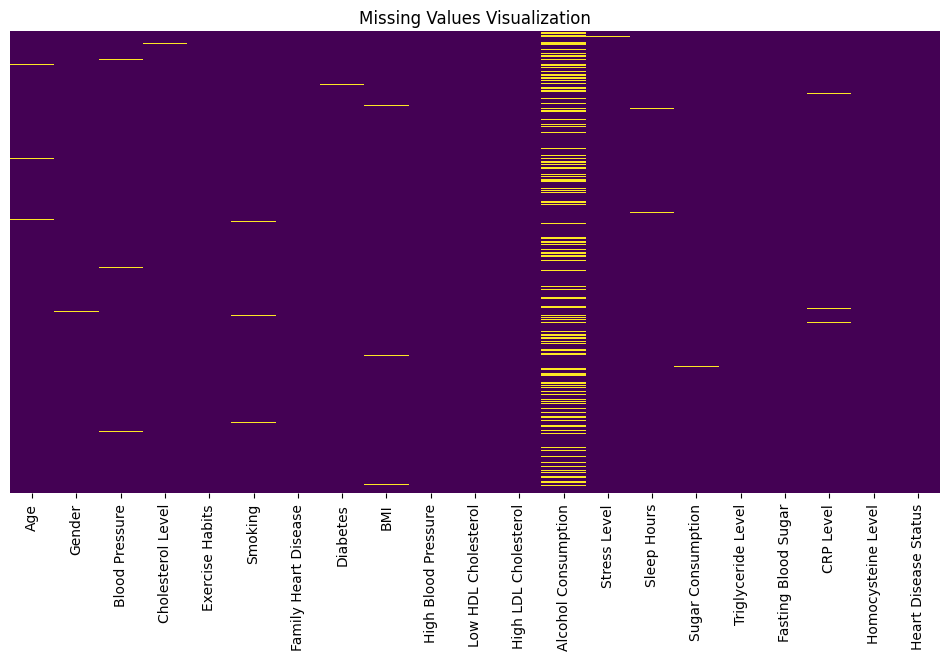

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap='viridis'
)

plt.title("Missing Values Visualization")
plt.show()

In [ ]:
print(
    "Missing target values:",
    df['Heart Disease Status'].isnull().sum()
)

Missing target values: 0


In [ ]:
# Separate numerical and categorical columns

numerical_features = df.drop(
    columns=['Heart Disease Status']
).select_dtypes(include='number').columns.tolist()

categorical_features = df.drop(
    columns=['Heart Disease Status']
).select_dtypes(include='object').columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['Age', 'Blood Pressure', 'Cholesterol Level', 'BMI', 'Sleep Hours', 'Triglyceride Level', 'Fasting Blood Sugar', 'CRP Level', 'Homocysteine Level']

Categorical Features:
['Gender', 'Exercise Habits', 'Smoking', 'Family Heart Disease', 'Diabetes', 'High Blood Pressure', 'Low HDL Cholesterol', 'High LDL Cholesterol', 'Alcohol Consumption', 'Stress Level', 'Sugar Consumption']


In [ ]:
# Handle missing numerical values

for col in numerical_features:
    df[col] = df[col].fillna(df[col].median())


# Handle missing categorical values

for col in categorical_features:

    if col == 'Alcohol Consumption':
        df[col] = df[col].fillna('Unknown')
    else:
        df[col] = df[col].fillna(df[col].mode()[0])


# Check missing values after imputation

print("Missing Values After Imputation:")
print(df.isnull().sum().sort_values(ascending=False))

Missing Values After Imputation:
Age                     0
Gender                  0
Blood Pressure          0
Cholesterol Level       0
Exercise Habits         0
Smoking                 0
Family Heart Disease    0
Diabetes                0
BMI                     0
High Blood Pressure     0
Low HDL Cholesterol     0
High LDL Cholesterol    0
Alcohol Consumption     0
Stress Level            0
Sleep Hours             0
Sugar Consumption       0
Triglyceride Level      0
Fasting Blood Sugar     0
CRP Level               0
Homocysteine Level      0
Heart Disease Status    0
dtype: int64


In [ ]:
from sklearn.preprocessing import LabelEncoder

# Create label encoders
label_encoders = {}

# Encode categorical columns
for col in categorical_features:

    le = LabelEncoder()

    df[col] = le.fit_transform(df[col].astype(str))

    label_encoders[col] = le

# Encode target column
target_encoder = LabelEncoder()

df['Heart Disease Status'] = target_encoder.fit_transform(
    df['Heart Disease Status'].astype(str)
)

print("Categorical Encoding Completed!")

print(df.head())

print("\nData Types:")
print(df.dtypes)

Categorical Encoding Completed!
    Age  Gender  Blood Pressure  Cholesterol Level  Exercise Habits  Smoking  \
0  56.0       1           153.0              155.0                0        1   
1  69.0       0           146.0              286.0                0        0   
2  46.0       1           126.0              216.0                1        0   
3  32.0       0           122.0              293.0                0        1   
4  60.0       1           166.0              242.0                1        1   

   Family Heart Disease  Diabetes        BMI  High Blood Pressure  ...  \
0                     1         0  24.991591                    1  ...   
1                     1         1  25.221799                    0  ...   
2                     0         0  29.855447                    0  ...   
3                     1         0  24.130477                    1  ...   
4                     1         1  20.486289                    1  ...   

   High LDL Cholesterol  Alcohol Consumpti

In [ ]:
# Separate features and target

X = df.drop(columns=['Heart Disease Status'])

y = df['Heart Disease Status']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

Features shape: (10000, 20)
Target shape: (10000,)

Target Distribution:
Heart Disease Status
0    8000
1    2000
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (8000, 20)
Testing Features: (2000, 20)
Training Target: (8000,)
Testing Target: (2000,)


In [ ]:
from sklearn.preprocessing import StandardScaler

# Initialize StandardScaler
scaler = StandardScaler()

# Fit and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

print("\nFeature Scaling Completed!")

Training data shape: (8000, 20)
Testing data shape: (2000, 20)

Feature Scaling Completed!


In [ ]:
!pip install imbalanced-learn

In [ ]:
from imblearn.over_sampling import SMOTE
from collections import Counter

# Check class distribution before SMOTE
print("Before SMOTE:", Counter(y_train))

# Apply SMOTE
smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_scaled,
    y_train
)

# Check distribution after SMOTE
print("\nAfter SMOTE:", Counter(y_train_balanced))

print("\nBalanced training shape:", X_train_balanced.shape)

Before SMOTE: Counter({0: 6400, 1: 1600})

After SMOTE: Counter({0: 6400, 1: 6400})

Balanced training shape: (12800, 20)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Initialize model
lr_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

# Train model
lr_model.fit(X_train_balanced, y_train_balanced)

# Predictions
y_pred_lr = lr_model.predict(X_test_scaled)

# Accuracy
print("Logistic Regression Accuracy:",
      accuracy_score(y_test, y_pred_lr))

# Classification report
print(classification_report(y_test, y_pred_lr))

Logistic Regression Accuracy: 0.51
              precision    recall  f1-score   support

           0       0.78      0.53      0.64      1600
           1       0.18      0.41      0.25       400

    accuracy                           0.51      2000
   macro avg       0.48      0.47      0.44      2000
weighted avg       0.66      0.51      0.56      2000



In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# Initialize Decision Tree
dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

# Train model
dt_model.fit(X_train_balanced, y_train_balanced)

# Predictions
y_pred_dt = dt_model.predict(X_test_scaled)

# Accuracy
print("Decision Tree Accuracy:",
      accuracy_score(y_test, y_pred_dt))

# Classification report
print(classification_report(y_test, y_pred_dt))

Decision Tree Accuracy: 0.7995
              precision    recall  f1-score   support

           0       0.80      1.00      0.89      1600
           1       0.00      0.00      0.00       400

    accuracy                           0.80      2000
   macro avg       0.40      0.50      0.44      2000
weighted avg       0.64      0.80      0.71      2000



In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Initialize Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    class_weight='balanced'
)

# Train model
rf_model.fit(X_train_balanced, y_train_balanced)

# Predictions
y_pred_rf = rf_model.predict(X_test_scaled)

# Accuracy
print("Random Forest Accuracy:",
      accuracy_score(y_test, y_pred_rf))

# Classification Report
print(classification_report(y_test, y_pred_rf))


Random Forest Accuracy: 0.7855
              precision    recall  f1-score   support

           0       0.80      0.98      0.88      1600
           1       0.16      0.02      0.03       400

    accuracy                           0.79      2000
   macro avg       0.48      0.50      0.46      2000
weighted avg       0.67      0.79      0.71      2000



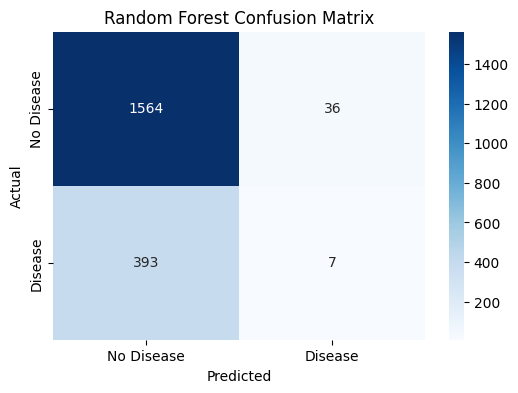

In [ ]:

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Disease', 'Disease'],
    yticklabels=['No Disease', 'Disease']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Random Forest Confusion Matrix')
plt.show()


In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Initialize Random Forest
rf_model2 = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    class_weight='balanced'
)

# Train without SMOTE
rf_model2.fit(X_train_scaled, y_train)

# Predictions
y_pred_rf2 = rf_model2.predict(X_test_scaled)

# Evaluate
print("Accuracy:", accuracy_score(y_test, y_pred_rf2))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf2))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf2))


Accuracy: 0.768

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.95      0.87      1600
           1       0.17      0.04      0.06       400

    accuracy                           0.77      2000
   macro avg       0.48      0.49      0.47      2000
weighted avg       0.67      0.77      0.71      2000


Confusion Matrix:
[[1520   80]
 [ 384   16]]


In [ ]:
!pip install xgboost


In [ ]:

from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Initialize XGBoost
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    scale_pos_weight=4,
    random_state=42,
    eval_metric='logloss'
)

# Train model
xgb_model.fit(X_train_scaled, y_train)

# Predictions
y_pred_xgb = xgb_model.predict(X_test_scaled)

# Evaluate model
print("XGBoost Accuracy:",
      accuracy_score(y_test, y_pred_xgb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))


XGBoost Accuracy: 0.5785

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.63      0.71      1600
           1       0.20      0.37      0.26       400

    accuracy                           0.58      2000
   macro avg       0.50      0.50      0.48      2000
weighted avg       0.68      0.58      0.62      2000


Confusion Matrix:
[[1009  591]
 [ 252  148]]


In [ ]:

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Initialize model
gb_model = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

# Train using balanced training data
gb_model.fit(X_train_balanced, y_train_balanced)

# Predict
y_pred_gb = gb_model.predict(X_test_scaled)

# Evaluate
print("Gradient Boosting Accuracy:",
      accuracy_score(y_test, y_pred_gb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_gb))


Gradient Boosting Accuracy: 0.8

Classification Report:
              precision    recall  f1-score   support

           0       0.80      1.00      0.89      1600
           1       0.00      0.00      0.00       400

    accuracy                           0.80      2000
   macro avg       0.40      0.50      0.44      2000
weighted avg       0.64      0.80      0.71      2000


Confusion Matrix:
[[1600    0]
 [ 400    0]]


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:

import numpy as np
from collections import Counter

# Check training distribution
print("Training distribution:",
      Counter(y_train_balanced))

# Check predicted classes
print("Predicted distribution:",
      Counter(y_pred_gb))

# Check prediction probabilities
y_prob_gb = gb_model.predict_proba(X_test_scaled)[:, 1]

print("Minimum probability:", y_prob_gb.min())
print("Maximum probability:", y_prob_gb.max())
print("Mean probability:", y_prob_gb.mean())

# Check probability distribution
print("Probabilities above 0.5:",
      np.sum(y_prob_gb >= 0.5))


Training distribution: Counter({0: 6400, 1: 6400})
Predicted distribution: Counter({np.int64(0): 2000})
Minimum probability: 0.0823826859905405
Maximum probability: 0.47262905248454873
Mean probability: 0.27785252257650606
Probabilities above 0.5: 0


In [ ]:

from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Experiment with different thresholds
thresholds = [0.50, 0.45, 0.40, 0.35, 0.30, 0.25]

for threshold in thresholds:

    y_pred_threshold = (
        y_prob_gb >= threshold
    ).astype(int)

    print("\nThreshold:", threshold)

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred_threshold))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred_threshold,
        zero_division=0
    ))



Threshold: 0.5
Confusion Matrix:
[[1600    0]
 [ 400    0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.80      1.00      0.89      1600
           1       0.00      0.00      0.00       400

    accuracy                           0.80      2000
   macro avg       0.40      0.50      0.44      2000
weighted avg       0.64      0.80      0.71      2000


Threshold: 0.45
Confusion Matrix:
[[1599    1]
 [ 400    0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.80      1.00      0.89      1600
           1       0.00      0.00      0.00       400

    accuracy                           0.80      2000
   macro avg       0.40      0.50      0.44      2000
weighted avg       0.64      0.80      0.71      2000


Threshold: 0.4
Confusion Matrix:
[[1578   22]
 [ 396    4]]

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.99  

In [ ]:

import pandas as pd
import numpy as np

# Compare probabilities by actual class
results = pd.DataFrame({
    "Actual": y_test,
    "Probability": y_prob_gb
})

print("Probability distribution by class:")

print(
    results.groupby("Actual")["Probability"]
    .describe()
)


Probability distribution by class:
         count      mean       std       min       25%       50%       75%  \
Actual                                                                       
0       1600.0  0.278206  0.057251  0.082383  0.240072  0.280311  0.317209   
1        400.0  0.276438  0.056371  0.115801  0.231667  0.277208  0.317785   

             max  
Actual            
0       0.472629  
1       0.422086  


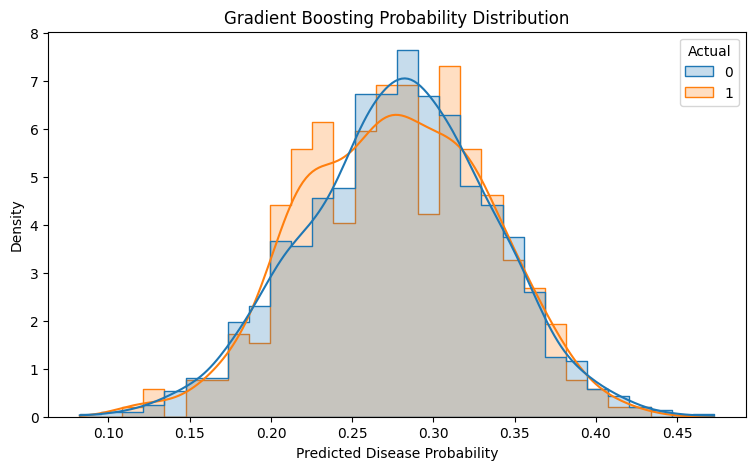

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.histplot(
    data=results,
    x="Probability",
    hue="Actual",
    bins=30,
    kde=True,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Gradient Boosting Probability Distribution")
plt.xlabel("Predicted Disease Probability")
plt.ylabel("Density")

plt.show()


ROC-AUC: 0.49055312500000003
PR-AUC: 0.1960893723144866


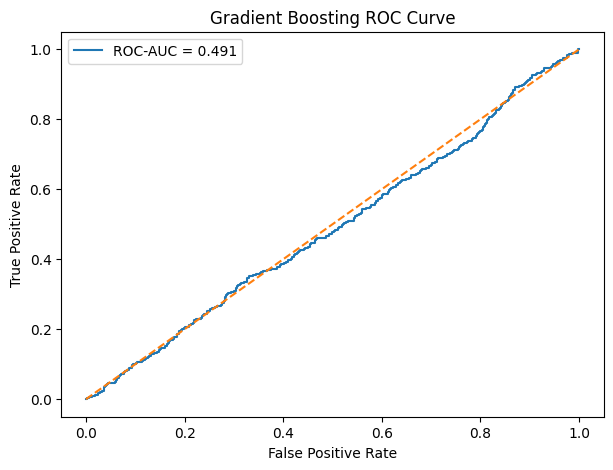

In [ ]:

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve
)
import matplotlib.pyplot as plt

# Calculate evaluation metrics
roc_auc = roc_auc_score(y_test, y_prob_gb)

pr_auc = average_precision_score(y_test, y_prob_gb)

print("ROC-AUC:", roc_auc)
print("PR-AUC:", pr_auc)

# Plot ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob_gb)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Gradient Boosting ROC Curve")
plt.legend()
plt.show()


In [ ]:

import numpy as np
from sklearn.metrics import roc_auc_score

# 1. Check class labels
print("Model classes:", gb_model.classes_)

print("Test distribution:",
      np.unique(y_test, return_counts=True))

print("Balanced training distribution:",
      np.unique(y_train_balanced, return_counts=True))

# 2. Check feature dimensions
print("Training shape:", X_train_balanced.shape)
print("Testing shape:", X_test_scaled.shape)

# 3. Check prediction probabilities
print("Probability shape:", y_prob_gb.shape)

print("Probability range:",
      y_prob_gb.min(), y_prob_gb.max())

# 4. Check normal and reversed AUC
print("Normal AUC:",
      roc_auc_score(y_test, y_prob_gb))

print("Reversed AUC:",
      roc_auc_score(y_test, 1 - y_prob_gb))

# 5. Check feature importance
import pandas as pd

if hasattr(X_train_balanced, "columns"):
    feature_names = X_train_balanced.columns
else:
    feature_names = [
        f"Feature_{i}" for i in range(X_train_balanced.shape[1])
    ]

importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": gb_model.feature_importances_
})

print(importance.sort_values(
    by="Importance", ascending=False
))


Model classes: [0 1]
Test distribution: (array([0, 1]), array([1600,  400]))
Balanced training distribution: (array([0, 1]), array([6400, 6400]))
Training shape: (12800, 20)
Testing shape: (2000, 20)
Probability shape: (2000,)
Probability range: 0.0823826859905405 0.47262905248454873
Normal AUC: 0.49055312500000003
Reversed AUC: 0.5094468750000001
       Feature  Importance
12  Feature_12    0.365268
15  Feature_15    0.193200
4    Feature_4    0.185623
13  Feature_13    0.078549
1    Feature_1    0.028334
5    Feature_5    0.019162
0    Feature_0    0.015002
17  Feature_17    0.014173
2    Feature_2    0.013777
8    Feature_8    0.010796
3    Feature_3    0.010294
7    Feature_7    0.009590
10  Feature_10    0.009369
18  Feature_18    0.009255
19  Feature_19    0.009164
11  Feature_11    0.009080
14  Feature_14    0.006101
16  Feature_16    0.006095
9    Feature_9    0.005525
6    Feature_6    0.001643


In [ ]:

import numpy as np
import pandas as pd

# Check missing and infinite values
print("Missing values:",
      np.isnan(X_train_balanced).sum())

print("Infinite values:",
      np.isinf(X_train_balanced).sum())

print("Test missing values:",
      np.isnan(X_test_scaled).sum())

# Check feature statistics
train_df = pd.DataFrame(X_train_balanced)
test_df = pd.DataFrame(X_test_scaled)

print("\nTraining feature statistics:")
print(train_df.describe().T)

print("\nTesting feature statistics:")
print(test_df.describe().T)

# Check target distribution
print("\nTraining labels:")
print(pd.Series(y_train_balanced).value_counts())

print("\nTesting labels:")
print(pd.Series(y_test).value_counts())

# Check feature importance concentration
print("\nTop 5 feature importance:")
print(importance.head(5))


Missing values: 0
Infinite values: 0
Test missing values: 0

Training feature statistics:
      count      mean       std       min       25%       50%       75%  \
0   12800.0 -0.006970  0.960230 -1.717322 -0.838078 -0.013786  0.810505   
1   12800.0 -0.017933  0.982773 -0.999500 -0.999500 -0.353359  1.000500   
2   12800.0 -0.000738  0.959741 -1.685546 -0.833959  0.017628  0.821046   
3   12800.0  0.008480  0.960649 -1.738982 -0.796648  0.007843  0.835287   
4   12800.0  0.008330  0.970918 -1.212502 -1.212502  0.004106  1.220714   
5   12800.0  0.008315  0.981435 -1.034080 -1.034080  0.731252  0.967043   
6   12800.0  0.001584  0.983735 -0.996506 -0.996506 -0.047320  1.003506   
7   12800.0  0.004769  0.981289 -1.002503 -1.002503  0.144895  0.997503   
8   12800.0  0.036869  0.958028 -1.770164 -0.756525  0.069533  0.850767   
9   12800.0  0.000251  0.981257 -1.013592 -1.013592  0.243057  0.986590   
10  12800.0  0.000848  0.981217 -0.990545 -0.990545 -0.137524  1.009546   
11  12800.

In [ ]:
print("Model classes:", gb_model.classes_)

print("Training shape:", X_train_balanced.shape)
print("Testing shape:", X_test_scaled.shape)

print("Training labels:")
print(pd.Series(y_train_balanced).value_counts())

print("Testing labels:")
print(pd.Series(y_test).value_counts())

print("Probability sample:")
print(y_prob_gb[:10])

print("Prediction sample:")
print(gb_model.predict(X_test_scaled)[:10])

Model classes: [0 1]
Training shape: (12800, 20)
Testing shape: (2000, 20)
Training labels:
Heart Disease Status
0    6400
1    6400
Name: count, dtype: int64
Testing labels:
Heart Disease Status
0    1600
1     400
Name: count, dtype: int64
Probability sample:
[0.33004189 0.36315197 0.30671073 0.27135453 0.20055749 0.39697787
 0.31344443 0.3097496  0.28457809 0.2860045 ]
Prediction sample:
[0 0 0 0 0 0 0 0 0 0]


In [ ]:
import joblib

joblib.dump(gb_model, '/content/gb_model.pkl')

['/content/gb_model.pkl']

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

joblib.dump(
    gb_model,
    '/content/drive/MyDrive/gb_model.pkl'
)

Mounted at /content/drive


['/content/drive/MyDrive/gb_model.pkl']

In [1]:
# Check whether previous variables are available

required_variables = [
    "gb_model",
    "X_train_balanced",
    "X_test_scaled",
    "y_train_balanced",
    "y_test",
    "y_prob_gb"
]

for var in required_variables:
    print(var, ":", var in globals())

gb_model : False
X_train_balanced : False
X_test_scaled : False
y_train_balanced : False
y_test : False
y_prob_gb : False


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

model_path = "/content/drive/MyDrive/gb_model.pkl"

print("Model exists:", os.path.exists(model_path))

Model exists: True


In [4]:
import joblib

model_path = "/content/drive/MyDrive/gb_model.pkl"

gb_model = joblib.load(model_path)

print("Model loaded successfully!")
print("Model:", gb_model)
print("Model classes:", gb_model.classes_)

Model loaded successfully!
Model: GradientBoostingClassifier(learning_rate=0.05, n_estimators=200,
                           random_state=42)
Model classes: [0 1]


In [6]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

In [7]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file.endswith(".pkl"):
            print(file)

gb_model.pkl


In [8]:
import os

for root, dirs, files in os.walk("/content"):
    if "drive" in root:
        continue

    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

/content/sample_data/california_housing_train.csv
/content/sample_data/mnist_test.csv
/content/sample_data/california_housing_test.csv
/content/sample_data/mnist_train_small.csv


In [9]:
from google.colab import files

uploaded = files.upload()

Saving archive (1).zip to archive (1).zip


In [10]:
import pandas as pd

file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name)

print("Dataset shape:", df.shape)
print("\nDataset columns:")
print(df.columns.tolist())

print("\nFirst 5 records:")
display(df.head())

Dataset shape: (10000, 21)

Dataset columns:
['Age', 'Gender', 'Blood Pressure', 'Cholesterol Level', 'Exercise Habits', 'Smoking', 'Family Heart Disease', 'Diabetes', 'BMI', 'High Blood Pressure', 'Low HDL Cholesterol', 'High LDL Cholesterol', 'Alcohol Consumption', 'Stress Level', 'Sleep Hours', 'Sugar Consumption', 'Triglyceride Level', 'Fasting Blood Sugar', 'CRP Level', 'Homocysteine Level', 'Heart Disease Status']

First 5 records:


,Age,Gender,Blood Pressure,Cholesterol Level,Exercise Habits,Smoking,Family Heart Disease,Diabetes,BMI,High Blood Pressure,...,High LDL Cholesterol,Alcohol Consumption,Stress Level,Sleep Hours,Sugar Consumption,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Heart Disease Status
0,56.0,Male,153.0,155.0,High,Yes,Yes,No,24.991591,Yes,...,No,High,Medium,7.633228,Medium,342.0,NaN,12.969246,12.387250,No
1,69.0,Female,146.0,286.0,High,No,Yes,Yes,25.221799,No,...,No,Medium,High,8.744034,Medium,133.0,157.0,9.355389,19.298875,No
2,46.0,Male,126.0,216.0,Low,No,No,No,29.855447,No,...,Yes,Low,Low,4.440440,Low,393.0,92.0,12.709873,11.230926,No
3,32.0,Female,122.0,293.0,High,Yes,Yes,No,24.130477,Yes,...,Yes,Low,High,5.249405,High,293.0,94.0,12.509046,5.961958,No
4,60.0,Male,166.0,242.0,Low,Yes,Yes,Yes,20.486289,Yes,...,No,Low,High,7.030971,High,263.0,154.0,10.381259,8.153887,No


In [11]:
print("Model:", gb_model)

print("Expected features:",
      gb_model.n_features_in_)

print("Dataset shape:", df.shape)

print("Dataset columns:")
print(df.columns.tolist())

Model: GradientBoostingClassifier(learning_rate=0.05, n_estimators=200,
                           random_state=42)
Expected features: 20
Dataset shape: (10000, 21)
Dataset columns:
['Age', 'Gender', 'Blood Pressure', 'Cholesterol Level', 'Exercise Habits', 'Smoking', 'Family Heart Disease', 'Diabetes', 'BMI', 'High Blood Pressure', 'Low HDL Cholesterol', 'High LDL Cholesterol', 'Alcohol Consumption', 'Stress Level', 'Sleep Hours', 'Sugar Consumption', 'Triglyceride Level', 'Fasting Blood Sugar', 'CRP Level', 'Homocysteine Level', 'Heart Disease Status']


In [12]:
print("All dataset columns:")

for i, col in enumerate(df.columns):
    print(f"{i}: {col}")

print("\nPossible target columns:")

for col in df.columns:
    if "heart disease status" in col.lower():
        print("Target:", col)
        print(df[col].value_counts(dropna=False))

All dataset columns:
0: Age
1: Gender
2: Blood Pressure
3: Cholesterol Level
4: Exercise Habits
5: Smoking
6: Family Heart Disease
7: Diabetes
8: BMI
9: High Blood Pressure
10: Low HDL Cholesterol
11: High LDL Cholesterol
12: Alcohol Consumption
13: Stress Level
14: Sleep Hours
15: Sugar Consumption
16: Triglyceride Level
17: Fasting Blood Sugar
18: CRP Level
19: Homocysteine Level
20: Heart Disease Status

Possible target columns:
Target: Heart Disease Status
Heart Disease Status
No     8000
Yes    2000
Name: count, dtype: int64


In [13]:
# Separate features and target
X = df.drop(columns=["Heart Disease Status"])
y = df["Heart Disease Status"].map({
    "No": 0,
    "Yes": 1
})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nCategorical columns:")
print(X.select_dtypes(include=["object", "category"]).columns.tolist())

print("\nModel feature names:")
print(getattr(gb_model, "feature_names_in_", "Not stored"))

print("\nFeature data types:")
print(X.dtypes)

Features shape: (10000, 20)
Target shape: (10000,)

Categorical columns:
['Gender', 'Exercise Habits', 'Smoking', 'Family Heart Disease', 'Diabetes', 'High Blood Pressure', 'Low HDL Cholesterol', 'High LDL Cholesterol', 'Alcohol Consumption', 'Stress Level', 'Sugar Consumption']

Model feature names:
Not stored

Feature data types:
Age                     float64
Gender                   object
Blood Pressure          float64
Cholesterol Level       float64
Exercise Habits          object
Smoking                  object
Family Heart Disease     object
Diabetes                 object
BMI                     float64
High Blood Pressure      object
Low HDL Cholesterol      object
High LDL Cholesterol     object
Alcohol Consumption      object
Stress Level             object
Sleep Hours             float64
Sugar Consumption        object
Triglyceride Level      float64
Fasting Blood Sugar     float64
CRP Level               float64
Homocysteine Level      float64
dtype: object


In [14]:
# Check categorical values

categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns

for col in categorical_cols:
    print("\n", col)
    print(X[col].value_counts(dropna=False))

# Check missing values
print("\nMissing values:")
print(X.isnull().sum())

# Check model feature count
print("\nExpected model features:",
      gb_model.n_features_in_)


 Gender
Gender
Male      5003
Female    4978
NaN         19
Name: count, dtype: int64

 Exercise Habits
Exercise Habits
High      3372
Medium    3332
Low       3271
NaN         25
Name: count, dtype: int64

 Smoking
Smoking
Yes    5123
No     4852
NaN      25
Name: count, dtype: int64

 Family Heart Disease
Family Heart Disease
No     5004
Yes    4975
NaN      21
Name: count, dtype: int64

 Diabetes
Diabetes
No     5018
Yes    4952
NaN      30
Name: count, dtype: int64

 High Blood Pressure
High Blood Pressure
Yes    5022
No     4952
NaN      26
Name: count, dtype: int64

 Low HDL Cholesterol
Low HDL Cholesterol
Yes    5000
No     4975
NaN      25
Name: count, dtype: int64

 High LDL Cholesterol
High LDL Cholesterol
No     5036
Yes    4938
NaN      26
Name: count, dtype: int64

 Alcohol Consumption
Alcohol Consumption
NaN       2586
Medium    2500
Low       2488
High      2426
Name: count, dtype: int64

 Stress Level
Stress Level
Medium    3387
Low       3320
High      3271
NaN       

In [15]:
import os

drive_path = "/content/drive/MyDrive"

for root, dirs, files in os.walk(drive_path):
    for file in files:
        if file.endswith((".pkl", ".joblib", ".sav")):
            print(os.path.join(root, file))

/content/drive/MyDrive/gb_model.pkl


In [16]:
print("Model:", gb_model)

print("Expected features:",
      gb_model.n_features_in_)

if hasattr(gb_model, "feature_names_in_"):
    print("Feature names:")
    print(gb_model.feature_names_in_)
else:
    print("Feature names were not stored.")

Model: GradientBoostingClassifier(learning_rate=0.05, n_estimators=200,
                           random_state=42)
Expected features: 20
Feature names were not stored.


In [17]:
print("Original training distribution:")
print(y_train.value_counts())

print("\nBalanced training distribution:")
print(pd.Series(y_train_balanced).value_counts())

print("\nTest distribution:")
print(y_test.value_counts())

Original training distribution:


NameError: name 'y_train' is not defined

In [19]:
print("Available training/testing variables:")

for name in list(globals().keys()):
    if "train" in name.lower() or "test" in name.lower():
        print(name)

Available training/testing variables:


In [20]:
print("Gradient Boosting model:", 'gb_model' in globals())
print("XGBoost model:", 'xgb_model' in globals())
print("Dataset:", 'df' in globals())
print("Balanced training data:", 'X_train_balanced' in globals())

Gradient Boosting model: True
XGBoost model: False
Dataset: True
Balanced training data: False


In [21]:
import os

from google.colab import drive
drive.mount('/content/drive')

model_folder = "/content/drive/MyDrive"

for root, dirs, files in os.walk(model_folder):
    for file in files:
        if file.endswith((".pkl", ".joblib")):
            print(os.path.join(root, file))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/gb_model.pkl


In [22]:
print("Dataset shape:", df.shape)

print("\nDataset columns:")
print(df.columns.tolist())

print("\nTarget distribution:")
print(df["Heart Disease Status"].value_counts(dropna=False))

Dataset shape: (10000, 21)

Dataset columns:
['Age', 'Gender', 'Blood Pressure', 'Cholesterol Level', 'Exercise Habits', 'Smoking', 'Family Heart Disease', 'Diabetes', 'BMI', 'High Blood Pressure', 'Low HDL Cholesterol', 'High LDL Cholesterol', 'Alcohol Consumption', 'Stress Level', 'Sleep Hours', 'Sugar Consumption', 'Triglyceride Level', 'Fasting Blood Sugar', 'CRP Level', 'Homocysteine Level', 'Heart Disease Status']

Target distribution:
Heart Disease Status
No     8000
Yes    2000
Name: count, dtype: int64


In [23]:
# Check existing project variables

check_variables = [
    'df',
    'gb_model',
    'xgb_model',
    'scaler',
    'X_train',
    'X_test',
    'y_train',
    'y_test',
    'X_train_scaled',
    'X_test_scaled',
    'X_train_balanced',
    'y_train_balanced'
]

for var in check_variables:
    print(var, ":", var in globals())

df : True
gb_model : True
xgb_model : False
scaler : False
X_train : False
X_test : False
y_train : False
y_test : False
X_train_scaled : False
X_test_scaled : False
X_train_balanced : False
y_train_balanced : False


In [24]:
from google.colab import drive
import joblib
import os

drive.mount('/content/drive')

model_path = "/content/drive/MyDrive/gb_model.pkl"

if os.path.exists(model_path):
    gb_model = joblib.load(model_path)
    print("Gradient Boosting model loaded!")
    print("Expected features:", gb_model.n_features_in_)
else:
    print("Model file not found!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Gradient Boosting model loaded!
Expected features: 20


In [25]:
print("Dataset shape:", df.shape)

print("\nTarget distribution:")
print(df["Heart Disease Status"].value_counts())

print("\nDataset columns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (10000, 21)

Target distribution:
Heart Disease Status
No     8000
Yes    2000
Name: count, dtype: int64

Dataset columns:
['Age', 'Gender', 'Blood Pressure', 'Cholesterol Level', 'Exercise Habits', 'Smoking', 'Family Heart Disease', 'Diabetes', 'BMI', 'High Blood Pressure', 'Low HDL Cholesterol', 'High LDL Cholesterol', 'Alcohol Consumption', 'Stress Level', 'Sleep Hours', 'Sugar Consumption', 'Triglyceride Level', 'Fasting Blood Sugar', 'CRP Level', 'Homocysteine Level', 'Heart Disease Status']

Missing values:
Age                       29
Gender                    19
Blood Pressure            19
Cholesterol Level         30
Exercise Habits           25
Smoking                   25
Family Heart Disease      21
Diabetes                  30
BMI                       22
High Blood Pressure       26
Low HDL Cholesterol       25
High LDL Cholesterol      26
Alcohol Consumption     2586
Stress Level              22
Sleep Hours               25
Sugar Consumption         30
Tr

In [26]:
# Identify numerical and categorical columns

target = "Heart Disease Status"

X = df.drop(columns=[target])
y = df[target]

numerical_cols = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical columns:")
print(numerical_cols)

print("\nCategorical columns:")
print(categorical_cols)

print("\nNumber of numerical features:", len(numerical_cols))
print("Number of categorical features:", len(categorical_cols))

Numerical columns:
['Age', 'Blood Pressure', 'Cholesterol Level', 'BMI', 'Sleep Hours', 'Triglyceride Level', 'Fasting Blood Sugar', 'CRP Level', 'Homocysteine Level']

Categorical columns:
['Gender', 'Exercise Habits', 'Smoking', 'Family Heart Disease', 'Diabetes', 'High Blood Pressure', 'Low HDL Cholesterol', 'High LDL Cholesterol', 'Alcohol Consumption', 'Stress Level', 'Sugar Consumption']

Number of numerical features: 9
Number of categorical features: 11


In [27]:
for col in categorical_cols:
    print("\n", col)
    print(df[col].value_counts(dropna=False))


 Gender
Gender
Male      5003
Female    4978
NaN         19
Name: count, dtype: int64

 Exercise Habits
Exercise Habits
High      3372
Medium    3332
Low       3271
NaN         25
Name: count, dtype: int64

 Smoking
Smoking
Yes    5123
No     4852
NaN      25
Name: count, dtype: int64

 Family Heart Disease
Family Heart Disease
No     5004
Yes    4975
NaN      21
Name: count, dtype: int64

 Diabetes
Diabetes
No     5018
Yes    4952
NaN      30
Name: count, dtype: int64

 High Blood Pressure
High Blood Pressure
Yes    5022
No     4952
NaN      26
Name: count, dtype: int64

 Low HDL Cholesterol
Low HDL Cholesterol
Yes    5000
No     4975
NaN      25
Name: count, dtype: int64

 High LDL Cholesterol
High LDL Cholesterol
No     5036
Yes    4938
NaN      26
Name: count, dtype: int64

 Alcohol Consumption
Alcohol Consumption
NaN       2586
Medium    2500
Low       2488
High      2426
Name: count, dtype: int64

 Stress Level
Stress Level
Medium    3387
Low       3320
High      3271
NaN       

In [28]:
for col in categorical_cols:
    print(f"\n{col}")
    print("Unique values:", df[col].unique())
    print("Missing values:", df[col].isnull().sum())


Gender
Unique values: ['Male' 'Female' nan]
Missing values: 19

Exercise Habits
Unique values: ['High' 'Low' 'Medium' nan]
Missing values: 25

Smoking
Unique values: ['Yes' 'No' nan]
Missing values: 25

Family Heart Disease
Unique values: ['Yes' 'No' nan]
Missing values: 21

Diabetes
Unique values: ['No' 'Yes' nan]
Missing values: 30

High Blood Pressure
Unique values: ['Yes' 'No' nan]
Missing values: 26

Low HDL Cholesterol
Unique values: ['Yes' 'No' nan]
Missing values: 25

High LDL Cholesterol
Unique values: ['No' 'Yes' nan]
Missing values: 26

Alcohol Consumption
Unique values: ['High' 'Medium' 'Low' nan]
Missing values: 2586

Stress Level
Unique values: ['Medium' 'High' 'Low' nan]
Missing values: 22

Sugar Consumption
Unique values: ['Medium' 'Low' 'High' nan]
Missing values: 30


In [29]:
df_clean = df.copy()

# Numerical missing values
for col in numerical_cols:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].median()
    )

# Categorical missing values
for col in categorical_cols:
    if col == "Alcohol Consumption":
        df_clean[col] = df_clean[col].fillna("Unknown")
    else:
        df_clean[col] = df_clean[col].fillna(
            df_clean[col].mode()[0]
        )

print("Remaining missing values:")
print(df_clean.isnull().sum().sum())

Remaining missing values:
0


In [30]:
# Separate input features and target

X = df_clean.drop("Heart Disease Status", axis=1)

y = df_clean["Heart Disease Status"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Input features shape: (10000, 20)
Target shape: (10000,)

Target distribution:
Heart Disease Status
No     8000
Yes    2000
Name: count, dtype: int64


In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (8000, 20)
X_test: (2000, 20)
y_train: (8000,)
y_test: (2000,)


In [32]:
from google.colab import drive
import os
import joblib

# Mount Google Drive
drive.mount('/content/drive')

# Create project backup folder
backup_folder = "/content/drive/MyDrive/Heart_Disease_Project"

os.makedirs(backup_folder, exist_ok=True)

print("Backup folder created successfully!")
print("Location:", backup_folder)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Backup folder created successfully!
Location: /content/drive/MyDrive/Heart_Disease_Project


In [33]:
import joblib

artifacts = {}

variables_to_save = [
    'df',
    'df_clean',
    'X',
    'y',
    'X_train',
    'X_test',
    'y_train',
    'y_test',
    'numerical_cols',
    'categorical_cols',
    'gb_model'
]

for var in variables_to_save:
    if var in globals():
        artifacts[var] = globals()[var]

checkpoint_path = backup_folder + "/preprocessing_checkpoint.pkl"

joblib.dump(artifacts, checkpoint_path)

print("Backup completed successfully!")
print("Saved variables:", list(artifacts.keys()))

Backup completed successfully!
Saved variables: ['df', 'df_clean', 'X', 'y', 'X_train', 'X_test', 'y_train', 'y_test', 'numerical_cols', 'categorical_cols', 'gb_model']


In [34]:
import joblib

artifacts = joblib.load(checkpoint_path)

print("Backup verification successful!")
print("Total saved variables:", len(artifacts))

print("\nSaved variables:")
for name in artifacts:
    print(name)

Backup verification successful!
Total saved variables: 11

Saved variables:
df
df_clean
X
y
X_train
X_test
y_train
y_test
numerical_cols
categorical_cols
gb_model


In [35]:
from sklearn.preprocessing import OneHotEncoder

# Create encoder
encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

# Fit on training data only
X_train_encoded = encoder.fit_transform(
    X_train[categorical_cols]
)

# Transform testing data
X_test_encoded = encoder.transform(
    X_test[categorical_cols]
)

print("Training categorical shape:", X_train_encoded.shape)
print("Testing categorical shape:", X_test_encoded.shape)

Training categorical shape: (8000, 27)
Testing categorical shape: (2000, 27)


In [36]:
import pandas as pd

# Get encoded feature names
encoded_columns = encoder.get_feature_names_out(categorical_cols)

# Convert encoded arrays into DataFrames
X_train_cat = pd.DataFrame(
    X_train_encoded,
    columns=encoded_columns,
    index=X_train.index
)

X_test_cat = pd.DataFrame(
    X_test_encoded,
    columns=encoded_columns,
    index=X_test.index
)

# Combine numerical and categorical features
X_train_final = pd.concat(
    [X_train[numerical_cols], X_train_cat], axis=1
)

X_test_final = pd.concat(
    [X_test[numerical_cols], X_test_cat], axis=1
)

print("Final training shape:", X_train_final.shape)
print("Final testing shape:", X_test_final.shape)

Final training shape: (8000, 36)
Final testing shape: (2000, 36)


In [37]:
print("Before SMOTE:")
print(y_train.value_counts())

print("\nClass distribution (%):")
print(y_train.value_counts(normalize=True) * 100)

Before SMOTE:
Heart Disease Status
No     6400
Yes    1600
Name: count, dtype: int64

Class distribution (%):
Heart Disease Status
No     80.0
Yes    20.0
Name: proportion, dtype: float64


In [38]:
from imblearn.over_sampling import SMOTE

# Initialize SMOTE
smote = SMOTE(random_state=42)

# Apply SMOTE only to training data
X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_final,
    y_train
)

# Check class distribution
print("After SMOTE:")
print(y_train_balanced.value_counts())

print("\nBalanced training shape:", X_train_balanced.shape)

After SMOTE:
Heart Disease Status
No     6400
Yes    6400
Name: count, dtype: int64

Balanced training shape: (12800, 36)


In [39]:
from sklearn.ensemble import GradientBoostingClassifier

# Initialize model
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Train model
gb_model.fit(
    X_train_balanced,
    y_train_balanced
)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [40]:
# Predict on testing data
y_pred = gb_model.predict(X_test_final)

# Prediction probabilities
y_prob = gb_model.predict_proba(X_test_final)[:, 1]

print("Predictions completed!")
print("Prediction shape:", y_pred.shape)

print("\nFirst 10 predictions:")
print(y_pred[:10])

print("\nFirst 10 probabilities:")
print(y_prob[:10])

Predictions completed!
Prediction shape: (2000,)

First 10 predictions:
['No' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'No']

First 10 probabilities:
[0.24694276 0.21959035 0.20727002 0.19585887 0.21138644 0.3245925
 0.2525324  0.29102854 0.21841546 0.21762519]


In [41]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, pos_label="Yes"
)

recall = recall_score(
    y_test, y_pred, pos_label="Yes"
)

f1 = f1_score(
    y_test, y_pred, pos_label="Yes"
)

roc_auc = roc_auc_score(
    (y_test == "Yes").astype(int),
    y_prob
)

# Display results
print("GRADIENT BOOSTING PERFORMANCE")
print("--------------------------------")

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("ROC-AUC:", roc_auc)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test, y_pred,
    labels=["No", "Yes"]
))

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


GRADIENT BOOSTING PERFORMANCE
--------------------------------
Accuracy: 0.8
Precision: 0.0
Recall: 0.0
F1 Score: 0.0
ROC-AUC: 0.47657656249999997

Classification Report:
              precision    recall  f1-score   support

          No       0.80      1.00      0.89      1600
         Yes       0.00      0.00      0.00       400

    accuracy                           0.80      2000
   macro avg       0.40      0.50      0.44      2000
weighted avg       0.64      0.80      0.71      2000


Confusion Matrix:
[[1600    0]
 [ 400    0]]


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [43]:
# Check model class order
print("Model classes:", gb_model.classes_)

# Check training predictions
train_pred = gb_model.predict(X_train_balanced)

print("\nTraining prediction distribution:")
print(pd.Series(train_pred).value_counts())

# Check testing predictions
print("\nTesting prediction distribution:")
print(pd.Series(y_pred).value_counts())

# Check probability distribution
print("\nProbability statistics:")
print(pd.Series(y_prob).describe())

# Compare actual test labels with probabilities
prob_check = pd.DataFrame({
    "Actual": y_test.reset_index(drop=True),
    "Probability_Yes": y_prob
})

print("\nAverage probability by actual class:")
print(prob_check.groupby("Actual")["Probability_Yes"].mean())

Model classes: ['No' 'Yes']

Training prediction distribution:
No     7997
Yes    4803
Name: count, dtype: int64

Testing prediction distribution:
No    2000
Name: count, dtype: int64

Probability statistics:
count    2000.000000
mean        0.217712
std         0.042484
min         0.078572
25%         0.189947
50%         0.218440
75%         0.244739
max         0.450189
dtype: float64

Average probability by actual class:
Actual
No     0.218363
Yes    0.215105
Name: Probability_Yes, dtype: float64


In [44]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Training predictions and probabilities
train_pred = gb_model.predict(X_train_balanced)
train_prob = gb_model.predict_proba(X_train_balanced)[:, 1]

# Testing predictions and probabilities
test_pred = gb_model.predict(X_test_final)
test_prob = gb_model.predict_proba(X_test_final)[:, 1]

# Performance comparison
print("TRAINING PERFORMANCE")
print("---------------------")
print("Accuracy:", accuracy_score(y_train_balanced, train_pred))
print("Precision:", precision_score(y_train_balanced, train_pred, pos_label="Yes", zero_division=0))
print("Recall:", recall_score(y_train_balanced, train_pred, pos_label="Yes", zero_division=0))
print("F1 Score:", f1_score(y_train_balanced, train_pred, pos_label="Yes", zero_division=0))
print("ROC-AUC:", roc_auc_score(
    (y_train_balanced == "Yes").astype(int), train_prob
))

print("\nTESTING PERFORMANCE")
print("-------------------")
print("Accuracy:", accuracy_score(y_test, test_pred))
print("Precision:", precision_score(y_test, test_pred, pos_label="Yes", zero_division=0))
print("Recall:", recall_score(y_test, test_pred, pos_label="Yes", zero_division=0))
print("F1 Score:", f1_score(y_test, test_pred, pos_label="Yes", zero_division=0))
print("ROC-AUC:", roc_auc_score(
    (y_test == "Yes").astype(int), test_prob
))


TRAINING PERFORMANCE
---------------------
Accuracy: 0.875234375
Precision: 1.0
Recall: 0.75046875
F1 Score: 0.8574488976167098
ROC-AUC: 0.9276734741210937

TESTING PERFORMANCE
-------------------
Accuracy: 0.8
Precision: 0.0
Recall: 0.0
F1 Score: 0.0
ROC-AUC: 0.47657656249999997


In [45]:

# Check target distribution
print("Original target distribution:")
print(y.value_counts())

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

# Check feature alignment
print("\nFeature alignment:")
print("Training shape:", X_train_final.shape)
print("Testing shape:", X_test_final.shape)

print(
    "Same columns:",
    X_train_final.columns.equals(X_test_final.columns)
)

# Check missing values
print("\nMissing values:")
print("Training:", X_train_final.isnull().sum().sum())
print("Testing:", X_test_final.isnull().sum().sum())

# Check infinite values
import numpy as np

print("\nInfinite values:")
print("Training:", np.isinf(X_train_final.select_dtypes(include=np.number)).sum().sum())
print("Testing:", np.isinf(X_test_final.select_dtypes(include=np.number)).sum().sum())


Original target distribution:
Heart Disease Status
No     8000
Yes    2000
Name: count, dtype: int64

Training target distribution:
Heart Disease Status
No     6400
Yes    1600
Name: count, dtype: int64

Testing target distribution:
Heart Disease Status
No     1600
Yes     400
Name: count, dtype: int64

Feature alignment:
Training shape: (8000, 36)
Testing shape: (2000, 36)
Same columns: True

Missing values:
Training: 0
Testing: 0

Infinite values:
Training: 0
Testing: 0


In [46]:

import pandas as pd
import numpy as np

# Compare training and testing feature distributions
train_mean = X_train_final.mean()
test_mean = X_test_final.mean()

train_std = X_train_final.std()

# Calculate standardized mean difference
difference = abs(train_mean - test_mean) / (train_std + 1e-8)

comparison = pd.DataFrame({
    "Training Mean": train_mean,
    "Testing Mean": test_mean,
    "Mean Difference": abs(train_mean - test_mean),
    "Standardized Difference": difference
})

# Display features with largest differences
comparison = comparison.sort_values(
    by="Standardized Difference",
    ascending=False
)

print("TOP 15 FEATURES WITH DISTRIBUTION DIFFERENCES")
print(comparison.head(15).round(4))


TOP 15 FEATURES WITH DISTRIBUTION DIFFERENCES
                            Training Mean  Testing Mean  Mean Difference  \
Low HDL Cholesterol_No             0.5048        0.4685           0.0363   
Low HDL Cholesterol_Yes            0.4952        0.5315           0.0362   
BMI                               29.1597       28.7477           0.4120   
Diabetes_Yes                       0.5012        0.4710           0.0302   
Diabetes_No                        0.4988        0.5290           0.0302   
Stress Level_Medium                0.3361        0.3600           0.0239   
Homocysteine Level                12.4217       12.5941           0.1724   
Alcohol Consumption_Medium         0.2534        0.2365           0.0169   
Stress Level_High                  0.3302        0.3145           0.0157   
Exercise Habits_Medium             0.3361        0.3215           0.0146   
Exercise Habits_Low                0.3244        0.3380           0.0136   
Triglyceride Level               251.2225 

In [47]:

# Predictions on original training data
train_original_pred = gb_model.predict(X_train_final)

train_original_prob = gb_model.predict_proba(
    X_train_final
)[:, 1]

from sklearn.metrics import classification_report, roc_auc_score

print("ORIGINAL TRAINING DATA PERFORMANCE")
print("-----------------------------------")

print(classification_report(
    y_train,
    train_original_pred,
    zero_division=0
))

print("Training ROC-AUC:",
      roc_auc_score(
          (y_train == "Yes").astype(int),
          train_original_prob
      ))

print("\nPrediction distribution:")
print(pd.Series(train_original_pred).value_counts())

print("\nProbability statistics:")
print(pd.Series(train_original_prob).describe())


ORIGINAL TRAINING DATA PERFORMANCE
-----------------------------------
              precision    recall  f1-score   support

          No       0.80      1.00      0.89      6400
         Yes       1.00      0.00      0.01      1600

    accuracy                           0.80      8000
   macro avg       0.90      0.50      0.45      8000
weighted avg       0.84      0.80      0.71      8000

Training ROC-AUC: 0.7106986816406249

Prediction distribution:
No     7995
Yes       5
Name: count, dtype: int64

Probability statistics:
count    8000.000000
mean        0.218556
std         0.045404
min         0.073918
25%         0.188669
50%         0.217880
75%         0.246385
max         0.567522
dtype: float64


In [48]:

import pandas as pd
import numpy as np

# Compare probabilities by actual class

train_check = pd.DataFrame({
    "Actual": y_train.values,
    "Probability_Yes": train_original_prob
})

test_check = pd.DataFrame({
    "Actual": y_test.values,
    "Probability_Yes": y_prob
})

print("TRAINING PROBABILITY BY CLASS")
print(train_check.groupby("Actual")[
    "Probability_Yes"
].describe())

print("\nTESTING PROBABILITY BY CLASS")
print(test_check.groupby("Actual")[
    "Probability_Yes"
].describe())

print("\nMODEL CLASSES:")
print(gb_model.classes_)


TRAINING PROBABILITY BY CLASS
         count      mean       std       min       25%       50%       75%  \
Actual                                                                       
No      6400.0  0.211321  0.041159  0.073918  0.183376  0.211922  0.239683   
Yes     1600.0  0.247496  0.049858  0.114523  0.215833  0.241804  0.271876   

             max  
Actual            
No      0.386980  
Yes     0.567522  

TESTING PROBABILITY BY CLASS
         count      mean       std       min       25%       50%       75%  \
Actual                                                                       
No      1600.0  0.218363  0.042303  0.078572  0.191183  0.218942  0.244913   
Yes      400.0  0.215105  0.043155  0.088132  0.183896  0.215909  0.244273   

             max  
Actual            
No      0.424352  
Yes     0.450189  

MODEL CLASSES:
['No' 'Yes']


In [49]:

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Calculate balanced sample weights
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

# Initialize model
gb_weighted = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Train on original data (without SMOTE)
gb_weighted.fit(
    X_train_final,
    y_train,
    sample_weight=sample_weights
)

# Predictions
y_pred_weighted = gb_weighted.predict(X_test_final)

# Get probability for Yes class
yes_index = list(gb_weighted.classes_).index("Yes")

y_prob_weighted = gb_weighted.predict_proba(
    X_test_final
)[:, yes_index]

# Evaluation
print("WEIGHTED GRADIENT BOOSTING PERFORMANCE")

print("Accuracy:",
      accuracy_score(y_test, y_pred_weighted))

print("Precision:",
      precision_score(y_test, y_pred_weighted,
                      pos_label="Yes", zero_division=0))

print("Recall:",
      recall_score(y_test, y_pred_weighted,
                   pos_label="Yes", zero_division=0))

print("F1 Score:",
      f1_score(y_test, y_pred_weighted,
               pos_label="Yes", zero_division=0))

print("ROC-AUC:",
      roc_auc_score(
          (y_test == "Yes").astype(int),
          y_prob_weighted
      ))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_weighted))

print("Confusion Matrix:")
print(confusion_matrix(
    y_test, y_pred_weighted,
    labels=["No", "Yes"]
))


WEIGHTED GRADIENT BOOSTING PERFORMANCE
Accuracy: 0.525
Precision: 0.18820861678004536
Recall: 0.415
F1 Score: 0.2589703588143526
ROC-AUC: 0.47765312499999996

Classification Report:
              precision    recall  f1-score   support

          No       0.79      0.55      0.65      1600
         Yes       0.19      0.41      0.26       400

    accuracy                           0.53      2000
   macro avg       0.49      0.48      0.45      2000
weighted avg       0.67      0.53      0.57      2000

Confusion Matrix:
[[884 716]
 [234 166]]


In [50]:

from sklearn.metrics import roc_auc_score
import pandas as pd

# Training probabilities
train_prob_weighted = gb_weighted.predict_proba(
    X_train_final
)[:, list(gb_weighted.classes_).index("Yes")]

# Testing probabilities
test_prob_weighted = gb_weighted.predict_proba(
    X_test_final
)[:, list(gb_weighted.classes_).index("Yes")]

# Create comparison dataframe
train_analysis = pd.DataFrame({
    "Actual": y_train.values,
    "Probability": train_prob_weighted
})

test_analysis = pd.DataFrame({
    "Actual": y_test.values,
    "Probability": test_prob_weighted
})

# ROC-AUC comparison
print("TRAIN ROC-AUC:",
      roc_auc_score(
          (y_train == "Yes").astype(int),
          train_prob_weighted
      ))

print("TEST ROC-AUC:",
      roc_auc_score(
          (y_test == "Yes").astype(int),
          test_prob_weighted
      ))

# Probability distribution
print("\nTRAIN PROBABILITY DISTRIBUTION")
print(train_analysis.groupby("Actual")[
    "Probability"
].mean())

print("\nTEST PROBABILITY DISTRIBUTION")
print(test_analysis.groupby("Actual")[
    "Probability"
].mean())

# Prediction distribution
print("\nTRAIN PREDICTIONS")
print(gb_weighted.predict(X_train_final).tolist()[:10])

print("\nTEST PREDICTION COUNTS")
print(pd.Series(y_pred_weighted).value_counts())


TRAIN ROC-AUC: 0.7741041503906251
TEST ROC-AUC: 0.47765312499999996

TRAIN PROBABILITY DISTRIBUTION
Actual
No     0.465991
Yes    0.534044
Name: Probability, dtype: float64

TEST PROBABILITY DISTRIBUTION
Actual
No     0.479656
Yes    0.473415
Name: Probability, dtype: float64

TRAIN PREDICTIONS
['No', 'Yes', 'Yes', 'Yes', 'Yes', 'No', 'No', 'No', 'Yes', 'Yes']

TEST PREDICTION COUNTS
No     1118
Yes     882
Name: count, dtype: int64


In [51]:

import pandas as pd
import numpy as np

# 1. Check dataset dimensions
print("Original dataset:", df_clean.shape)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

# 2. Check target distribution
print("\nTarget distribution:")
print(df_clean["Heart Disease Status"].value_counts())

# 3. Check duplicate records
print("\nDuplicate records:",
      df_clean.duplicated().sum())

# 4. Check missing values
print("\nMissing values:",
      df_clean.isnull().sum().sum())

# 5. Check feature columns
print("\nTraining columns:")
print(list(X_train.columns))

print("\nTesting columns:")
print(list(X_test.columns))

# 6. Check feature alignment
print("\nSame feature columns:",
      list(X_train.columns) == list(X_test.columns))

# 7. Check target alignment
print("\nTraining index alignment:",
      X_train.index.equals(y_train.index))

print("Testing index alignment:",
      X_test.index.equals(y_test.index))

# 8. Check target distribution in train/test
print("\nTraining target:")
print(y_train.value_counts(normalize=True))

print("\nTesting target:")
print(y_test.value_counts(normalize=True))


Original dataset: (10000, 21)
Training features: (8000, 20)
Testing features: (2000, 20)

Target distribution:
Heart Disease Status
No     8000
Yes    2000
Name: count, dtype: int64

Duplicate records: 0

Missing values: 0

Training columns:
['Age', 'Gender', 'Blood Pressure', 'Cholesterol Level', 'Exercise Habits', 'Smoking', 'Family Heart Disease', 'Diabetes', 'BMI', 'High Blood Pressure', 'Low HDL Cholesterol', 'High LDL Cholesterol', 'Alcohol Consumption', 'Stress Level', 'Sleep Hours', 'Sugar Consumption', 'Triglyceride Level', 'Fasting Blood Sugar', 'CRP Level', 'Homocysteine Level']

Testing columns:
['Age', 'Gender', 'Blood Pressure', 'Cholesterol Level', 'Exercise Habits', 'Smoking', 'Family Heart Disease', 'Diabetes', 'BMI', 'High Blood Pressure', 'Low HDL Cholesterol', 'High LDL Cholesterol', 'Alcohol Consumption', 'Stress Level', 'Sleep Hours', 'Sugar Consumption', 'Triglyceride Level', 'Fasting Blood Sugar', 'CRP Level', 'Homocysteine Level']

Same feature columns: True

T

TOP 20 IMPORTANT FEATURES
                       Feature  Importance
31            Stress Level_Low    0.117695
10                 Gender_Male    0.082224
34       Sugar Consumption_Low    0.080425
15                 Smoking_Yes    0.079133
9                Gender_Female    0.072432
16     Family Heart Disease_No    0.050236
20      High Blood Pressure_No    0.050095
22      Low HDL Cholesterol_No    0.046574
24     High LDL Cholesterol_No    0.046265
25    High LDL Cholesterol_Yes    0.041027
11        Exercise Habits_High    0.034444
28  Alcohol Consumption_Medium    0.029733
19                Diabetes_Yes    0.028626
35    Sugar Consumption_Medium    0.026120
30           Stress Level_High    0.025133
12         Exercise Habits_Low    0.024585
32         Stress Level_Medium    0.020196
21     High Blood Pressure_Yes    0.019682
13      Exercise Habits_Medium    0.018211
23     Low HDL Cholesterol_Yes    0.013187


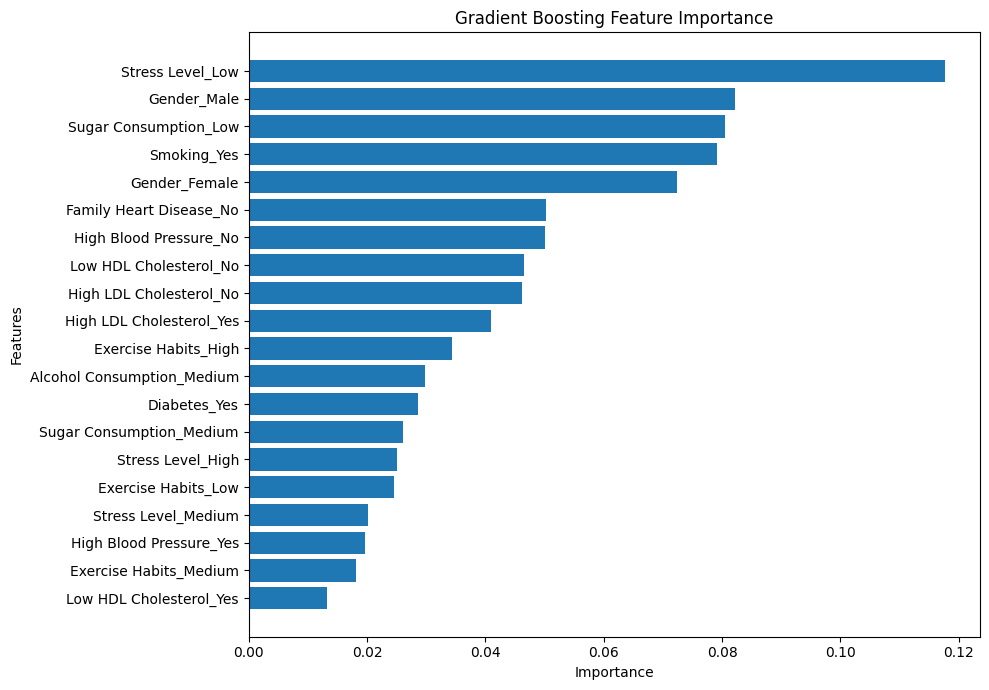

In [52]:

import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance
importance = pd.DataFrame({
    "Feature": X_train_balanced.columns,
    "Importance": gb_model.feature_importances_
})

# Sort importance
importance = importance.sort_values(
    by="Importance", ascending=False
)

print("TOP 20 IMPORTANT FEATURES")
print(importance.head(20))

# Visualize
plt.figure(figsize=(10, 7))

plt.barh(
    importance.head(20)["Feature"],
    importance.head(20)["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Gradient Boosting Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [53]:

import pandas as pd
import numpy as np

# Create probability analysis dataframe
probability_check = pd.DataFrame({
    "Actual": y_test.values,
    "Probability_Yes": y_prob
})

# Average probability for each actual class
print("AVERAGE PROBABILITY BY ACTUAL CLASS")

print(
    probability_check.groupby("Actual")[
        "Probability_Yes"
    ].agg(["count", "mean", "min", "max", "std"])
)

# Probability distribution
print("\nPROBABILITY DISTRIBUTION")

print(probability_check["Probability_Yes"].describe())

# Model classes
print("\nMODEL CLASSES:")
print(gb_model.classes_)


AVERAGE PROBABILITY BY ACTUAL CLASS
        count      mean       min       max       std
Actual                                               
No       1600  0.218363  0.078572  0.424352  0.042303
Yes       400  0.215105  0.088132  0.450189  0.043155

PROBABILITY DISTRIBUTION
count    2000.000000
mean        0.217712
std         0.042484
min         0.078572
25%         0.189947
50%         0.218440
75%         0.244739
max         0.450189
Name: Probability_Yes, dtype: float64

MODEL CLASSES:
['No' 'Yes']


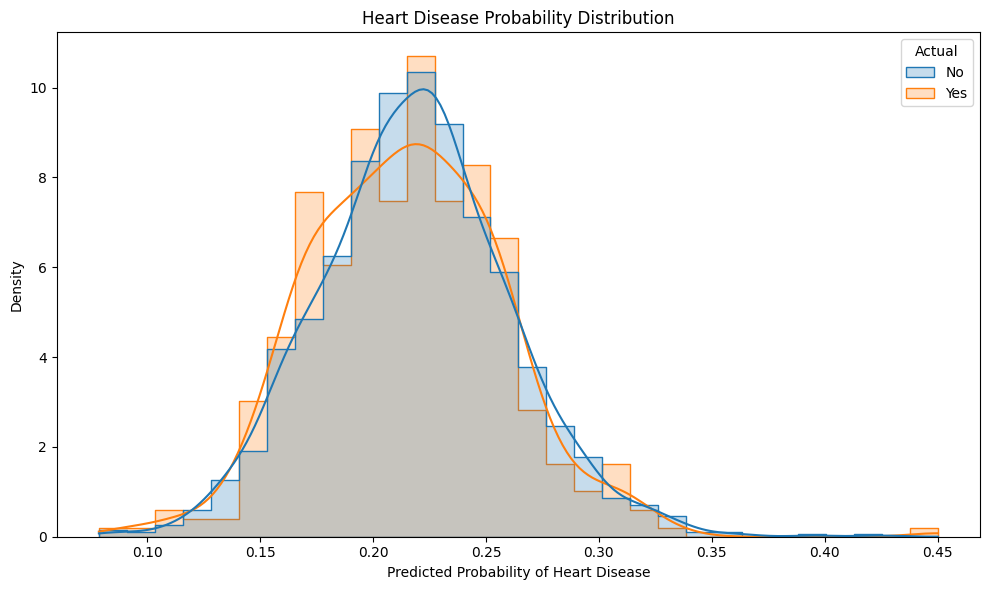

In [54]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.histplot(
    data=probability_check,
    x="Probability_Yes",
    hue="Actual",
    bins=30,
    kde=True,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Heart Disease Probability Distribution")
plt.xlabel("Predicted Probability of Heart Disease")
plt.ylabel("Density")

plt.tight_layout()
plt.show()


In [55]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score
)
import pandas as pd
import numpy as np

# Check target and feature alignment
print("Training shapes:", X_train_final.shape, y_train.shape)
print("Testing shapes:", X_test_final.shape, y_test.shape)

print("\nTraining index alignment:",
      X_train_final.index.equals(y_train.index))

print("Testing index alignment:",
      X_test_final.index.equals(y_test.index))

# Check target distribution
print("\nTraining target:")
print(y_train.value_counts())

print("\nTesting target:")
print(y_test.value_counts())

# Fresh predictions
y_pred_check = gb_model.predict(X_test_final)

y_prob_check = gb_model.predict_proba(
    X_test_final
)[:, list(gb_model.classes_).index("Yes")]

# Evaluation
print("\nCONFUSION MATRIX")
print(confusion_matrix(
    y_test,
    y_pred_check,
    labels=["No", "Yes"]
))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred_check,
    zero_division=0
))

print("\nROC-AUC:",
      roc_auc_score(
          (y_test == "Yes").astype(int),
          y_prob_check
      ))


Training shapes: (8000, 36) (8000,)
Testing shapes: (2000, 36) (2000,)

Training index alignment: True
Testing index alignment: True

Training target:
Heart Disease Status
No     6400
Yes    1600
Name: count, dtype: int64

Testing target:
Heart Disease Status
No     1600
Yes     400
Name: count, dtype: int64

CONFUSION MATRIX
[[1600    0]
 [ 400    0]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

          No       0.80      1.00      0.89      1600
         Yes       0.00      0.00      0.00       400

    accuracy                           0.80      2000
   macro avg       0.40      0.50      0.44      2000
weighted avg       0.64      0.80      0.71      2000


ROC-AUC: 0.47657656249999997


In [56]:

import numpy as np
import pandas as pd

# Check model classes
print("Model classes:", gb_model.classes_)

# Get positive-class probability
yes_index = list(gb_model.classes_).index("Yes")

train_prob = gb_model.predict_proba(
    X_train_final
)[:, yes_index]

test_prob = gb_model.predict_proba(
    X_test_final
)[:, yes_index]

print("\nTRAINING PROBABILITIES")
print(pd.Series(train_prob).describe())

print("\nTESTING PROBABILITIES")
print(pd.Series(test_prob).describe())

# Check probability ranges
print("\nTraining minimum:", train_prob.min())
print("Training maximum:", train_prob.max())

print("\nTesting minimum:", test_prob.min())
print("Testing maximum:", test_prob.max())

# Compare average probabilities
print("\nTESTING PROBABILITY BY ACTUAL CLASS")

prob_comparison = pd.DataFrame({
    "Actual": y_test.reset_index(drop=True),
    "Probability": test_prob
})

print(
    prob_comparison.groupby("Actual")[
        "Probability"
    ].agg(["count", "mean", "min", "max", "std"])
)


Model classes: ['No' 'Yes']

TRAINING PROBABILITIES
count    8000.000000
mean        0.218556
std         0.045404
min         0.073918
25%         0.188669
50%         0.217880
75%         0.246385
max         0.567522
dtype: float64

TESTING PROBABILITIES
count    2000.000000
mean        0.217712
std         0.042484
min         0.078572
25%         0.189947
50%         0.218440
75%         0.244739
max         0.450189
dtype: float64

Training minimum: 0.07391762745310634
Training maximum: 0.5675215083930623

Testing minimum: 0.07857166907786406
Testing maximum: 0.45018944445185965

TESTING PROBABILITY BY ACTUAL CLASS
        count      mean       min       max       std
Actual                                               
No       1600  0.218363  0.078572  0.424352  0.042303
Yes       400  0.215105  0.088132  0.450189  0.043155


In [57]:

import pandas as pd
import numpy as np

from sklearn.feature_selection import mutual_info_classif

# Combine training features and target
X_check = X_train_final.copy()

# Encode target
y_check = y_train.map({
    "No": 0,
    "Yes": 1
})

# Calculate feature correlations
correlations = X_check.corrwith(y_check)

print("FEATURE CORRELATION WITH TARGET")
print(
    correlations.abs()
    .sort_values(ascending=False)
    .head(20)
)

# Mutual information
mi_scores = mutual_info_classif(
    X_check,
    y_check,
    random_state=42
)

mi_results = pd.Series(
    mi_scores,
    index=X_check.columns
).sort_values(ascending=False)

print("\nTOP 20 MUTUAL INFORMATION FEATURES")
print(mi_results.head(20))


FEATURE CORRELATION WITH TARGET
BMI                           0.031086
Stress Level_Low              0.028366
Gender_Male                   0.024750
Gender_Female                 0.024750
Stress Level_Medium           0.022625
Sugar Consumption_High        0.018725
Age                           0.015874
Alcohol Consumption_Medium    0.013220
High LDL Cholesterol_No       0.010001
High LDL Cholesterol_Yes      0.010001
Sugar Consumption_Medium      0.009459
Sugar Consumption_Low         0.009223
Smoking_No                    0.008880
Smoking_Yes                   0.008880
Alcohol Consumption_Low       0.008682
Sleep Hours                   0.007879
Exercise Habits_Medium        0.007409
Alcohol Consumption_High      0.006568
Homocysteine Level            0.006383
Fasting Blood Sugar           0.005828
dtype: float64

TOP 20 MUTUAL INFORMATION FEATURES
High LDL Cholesterol_No        0.006895
Homocysteine Level             0.005280
Alcohol Consumption_Medium     0.004786
High LDL Choleste

In [58]:

import pandas as pd
import numpy as np

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

# Encode target
y_binary = y_train.map({
    "No": 0,
    "Yes": 1
})

# Models
models = {
    "Dummy Baseline": DummyClassifier(
        strategy="most_frequent"
    ),

    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        )
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train_final,
        y_binary,
        cv=cv,
        scoring={
            "roc_auc": "roc_auc",
            "balanced_accuracy": "balanced_accuracy",
            "recall": "recall"
        }
    )

    results.append({
        "Model": name,
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "Balanced Accuracy": scores[
            "test_balanced_accuracy"
        ].mean(),
        "Recall": scores["test_recall"].mean()
    })

comparison = pd.DataFrame(results)

print(comparison.round(4))


                 Model  ROC-AUC  Balanced Accuracy  Recall
0       Dummy Baseline   0.5000             0.5000  0.0000
1  Logistic Regression   0.5109             0.5018  0.4894
2        Random Forest   0.5169             0.5000  0.0000
3    Gradient Boosting   0.5102             0.5001  0.0006


In [59]:

# STEP 59: DATA INTEGRITY CHECK

print("TRAINING DATA SHAPES")
print("X:", X_train_final.shape)
print("y:", y_train.shape)

print("\nINDEX ALIGNMENT")
print(
    "Indexes match:",
    X_train_final.index.equals(y_train.index)
)

print("\nTARGET VALUES")
print(y_train.value_counts())

print("\nTARGET MISSING VALUES")
print(y_train.isna().sum())

print("\nFEATURE MISSING VALUES")
print(X_train_final.isna().sum().sum())

print("\nDUPLICATE TRAINING ROWS")
print(X_train_final.duplicated().sum())

print("\nFEATURE VARIANCE")
print(
    X_train_final.var()
    .sort_values()
    .head(15)
)

print("\nTARGET CORRELATION CHECK")
print(
    X_train_final.corrwith(
        y_train.map({"No": 0, "Yes": 1})
    ).abs().sort_values(ascending=False).head(10)
)


TRAINING DATA SHAPES
X: (8000, 36)
y: (8000,)

INDEX ALIGNMENT
Indexes match: True

TARGET VALUES
Heart Disease Status
No     6400
Yes    1600
Name: count, dtype: int64

TARGET MISSING VALUES
0

FEATURE MISSING VALUES
0

DUPLICATE TRAINING ROWS
0

FEATURE VARIANCE
Alcohol Consumption_High       0.183394
Alcohol Consumption_Low        0.186582
Alcohol Consumption_Medium     0.189200
Alcohol Consumption_Unknown    0.190792
Exercise Habits_Low            0.219183
Sugar Consumption_Medium       0.220099
Stress Level_High              0.221213
Sugar Consumption_High         0.221509
Stress Level_Low               0.222347
Stress Level_Medium            0.223173
Exercise Habits_Medium         0.223173
Exercise Habits_High           0.224268
Sugar Consumption_Low          0.225025
Smoking_No                     0.249751
Smoking_Yes                    0.249751
dtype: float64

TARGET CORRELATION CHECK
BMI                           0.031086
Stress Level_Low              0.028366
Gender_Male     

In [63]:
import pandas as pd
import zipfile

with zipfile.ZipFile('/content/archive.zip') as z:
    df = pd.read_csv(z.open('heart_disease.csv'))

print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum().sort_values(ascending=False))

print("\nTarget Distribution:")
print(df['Heart Disease Status'].value_counts())

print("\nTarget Percentages:")
print(
    df['Heart Disease Status']
    .value_counts(normalize=True) * 100
)

FileNotFoundError: [Errno 2] No such file or directory: '/content/archive.zip'

In [64]:
import os

for root, dirs, files in os.walk('/content'):
    for file in files:
        if file.endswith(('.zip', '.csv')):
            print(os.path.join(root, file))

/content/archive (1).zip
/content/drive/MyDrive/archive (1).zip
/content/sample_data/california_housing_train.csv
/content/sample_data/mnist_test.csv
/content/sample_data/california_housing_test.csv
/content/sample_data/mnist_train_small.csv


In [65]:
import pandas as pd
import zipfile

zip_path = '/content/archive (1).zip'

with zipfile.ZipFile(zip_path, 'r') as z:
    print("Files inside ZIP:", z.namelist())

    csv_file = [f for f in z.namelist()
                if f.endswith('.csv')][0]

    df = pd.read_csv(z.open(csv_file))

print("Dataset Shape:", df.shape)
print(df.head())

Files inside ZIP: ['heart_disease.csv']
Dataset Shape: (10000, 21)
    Age  Gender  Blood Pressure  Cholesterol Level Exercise Habits Smoking  \
0  56.0    Male           153.0              155.0            High     Yes   
1  69.0  Female           146.0              286.0            High      No   
2  46.0    Male           126.0              216.0             Low      No   
3  32.0  Female           122.0              293.0            High     Yes   
4  60.0    Male           166.0              242.0             Low     Yes   

  Family Heart Disease Diabetes        BMI High Blood Pressure  ...  \
0                  Yes       No  24.991591                 Yes  ...   
1                  Yes      Yes  25.221799                  No  ...   
2                   No       No  29.855447                  No  ...   
3                  Yes       No  24.130477                 Yes  ...   
4                  Yes      Yes  20.486289                 Yes  ...   

  High LDL Cholesterol Alcohol Consum

In [66]:

# 1. Dataset information
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

# 2. Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 3. Duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

# 4. Target distribution
print("\nTarget Distribution:")
print(df['Heart Disease Status'].value_counts())

# 5. Target percentage
print("\nTarget Percentage:")
print(
    df['Heart Disease Status']
    .value_counts(normalize=True) * 100
)

# 6. Data types
print("\nData Types:")
print(df.dtypes)


Dataset Shape: (10000, 21)

Column Names:
['Age', 'Gender', 'Blood Pressure', 'Cholesterol Level', 'Exercise Habits', 'Smoking', 'Family Heart Disease', 'Diabetes', 'BMI', 'High Blood Pressure', 'Low HDL Cholesterol', 'High LDL Cholesterol', 'Alcohol Consumption', 'Stress Level', 'Sleep Hours', 'Sugar Consumption', 'Triglyceride Level', 'Fasting Blood Sugar', 'CRP Level', 'Homocysteine Level', 'Heart Disease Status']

Missing Values:
Age                       29
Gender                    19
Blood Pressure            19
Cholesterol Level         30
Exercise Habits           25
Smoking                   25
Family Heart Disease      21
Diabetes                  30
BMI                       22
High Blood Pressure       26
Low HDL Cholesterol       25
High LDL Cholesterol      26
Alcohol Consumption     2586
Stress Level              22
Sleep Hours               25
Sugar Consumption         30
Triglyceride Level        26
Fasting Blood Sugar       22
CRP Level                 26
Homocystein

In [67]:

# Investigate missing values by target class

print("Missing values by target class:")

for col in df.columns:
    if df[col].isnull().sum() > 0:
        print(f"\n{col}")
        print(
            df.groupby('Heart Disease Status')[col]
            .apply(lambda x: x.isnull().sum())
        )

# Check categorical values
print("\nAlcohol Consumption categories:")
print(df['Alcohol Consumption'].value_counts(dropna=False))

# Check target distribution
print("\nTarget distribution:")
print(df['Heart Disease Status'].value_counts())


Missing values by target class:

Age
Heart Disease Status
No     25
Yes     4
Name: Age, dtype: int64

Gender
Heart Disease Status
No     18
Yes     1
Name: Gender, dtype: int64

Blood Pressure
Heart Disease Status
No     15
Yes     4
Name: Blood Pressure, dtype: int64

Cholesterol Level
Heart Disease Status
No     25
Yes     5
Name: Cholesterol Level, dtype: int64

Exercise Habits
Heart Disease Status
No     24
Yes     1
Name: Exercise Habits, dtype: int64

Smoking
Heart Disease Status
No     19
Yes     6
Name: Smoking, dtype: int64

Family Heart Disease
Heart Disease Status
No     14
Yes     7
Name: Family Heart Disease, dtype: int64

Diabetes
Heart Disease Status
No     24
Yes     6
Name: Diabetes, dtype: int64

BMI
Heart Disease Status
No     20
Yes     2
Name: BMI, dtype: int64

High Blood Pressure
Heart Disease Status
No     21
Yes     5
Name: High Blood Pressure, dtype: int64

Low HDL Cholesterol
Heart Disease Status
No     22
Yes     3
Name: Low HDL Cholesterol, dtype: int64

H

In [68]:

import pandas as pd

# Create a copy of original dataset
df_clean = df.copy()

# Separate numerical and categorical columns
categorical_cols = df_clean.select_dtypes(
    include='object'
).columns.tolist()

numerical_cols = df_clean.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Preserve missing alcohol values
df_clean['Alcohol Consumption'] = (
    df_clean['Alcohol Consumption'].fillna('Unknown')
)

# Fill other categorical missing values
for col in categorical_cols:
    if col != 'Alcohol Consumption':
        df_clean[col] = df_clean[col].fillna(
            df_clean[col].mode()[0]
        )

# Fill numerical missing values
for col in numerical_cols:
    if col != 'Heart Disease Status':
        df_clean[col] = df_clean[col].fillna(
            df_clean[col].median()
        )

# Verify
print("Remaining missing values:")
print(df_clean.isnull().sum().sum())

print("\nCleaned dataset shape:")
print(df_clean.shape)

print("\nAlcohol categories:")
print(df_clean['Alcohol Consumption'].value_counts())


Remaining missing values:
0

Cleaned dataset shape:
(10000, 21)

Alcohol categories:
Alcohol Consumption
Unknown    2586
Medium     2500
Low        2488
High       2426
Name: count, dtype: int64


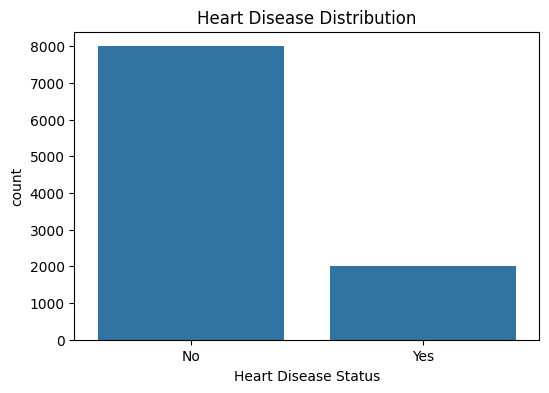

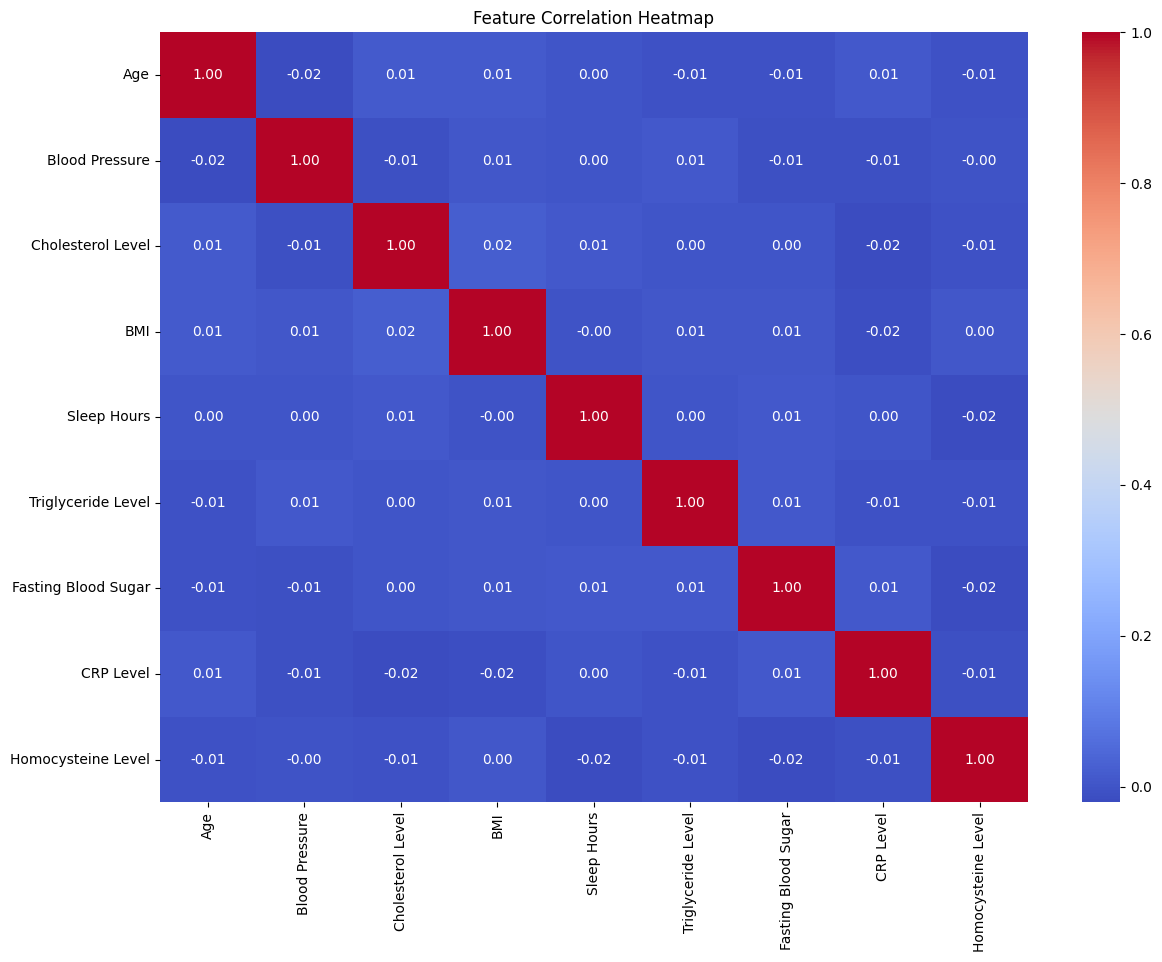

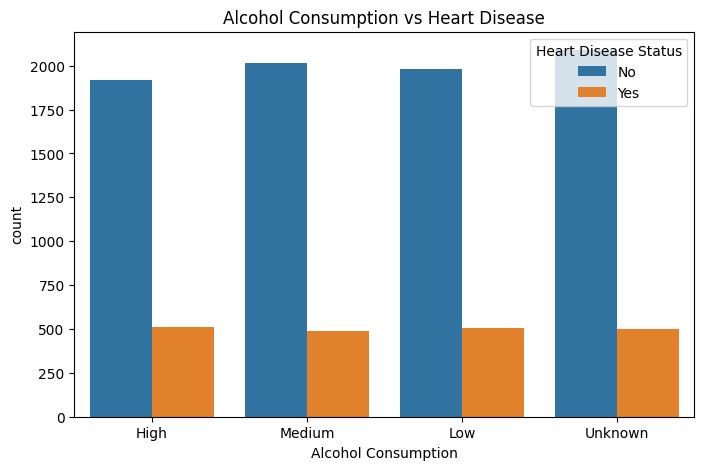

In [69]:

import matplotlib.pyplot as plt
import seaborn as sns

# Target distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df_clean, x='Heart Disease Status')
plt.title('Heart Disease Distribution')
plt.show()

# Numerical feature correlation
plt.figure(figsize=(14, 10))

numeric_df = df_clean.select_dtypes(
    include=['int64', 'float64']
)

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Feature Correlation Heatmap')
plt.show()

# Target distribution by alcohol consumption
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x='Alcohol Consumption',
    hue='Heart Disease Status'
)

plt.title('Alcohol Consumption vs Heart Disease')
plt.show()


In [70]:

# TARGET RELATIONSHIP ANALYSIS

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

target = 'Heart Disease Status'

# 1. Categorical features vs target
categorical_cols = df_clean.select_dtypes(
    include=['object', 'category']
).columns.drop(target)

print("CATEGORICAL FEATURES VS HEART DISEASE\n")

for col in categorical_cols:
    print(f"\n--- {col} ---")

    result = pd.crosstab(
        df_clean[col],
        df_clean[target],
        normalize='index'
    ) * 100

    print(result.round(2))


# 2. Numerical features vs target
numeric_cols = df_clean.select_dtypes(
    include=['int64', 'float64']
).columns

print("\nNUMERICAL FEATURES VS HEART DISEASE\n")

for col in numeric_cols:
    print(f"\n--- {col} ---")

    print(
        df_clean.groupby(target)[col]
        .agg(['mean', 'median', 'std'])
        .round(2)
    )


# 3. Numerical feature correlation with target
df_analysis = df_clean.copy()

df_analysis[target] = df_analysis[target].map({
    'No': 0,
    'Yes': 1
})

correlations = (
    df_analysis[numeric_cols.tolist() + [target]]
    .corr()[target]
    .drop(target)
    .sort_values(ascending=False)
)

print("\nFEATURE CORRELATION WITH TARGET\n")
print(correlations)


CATEGORICAL FEATURES VS HEART DISEASE


--- Gender ---
Heart Disease Status     No    Yes
Gender                            
Female                79.31  20.69
Male                  80.68  19.32

--- Exercise Habits ---
Heart Disease Status     No    Yes
Exercise Habits                   
High                  80.10  19.90
Low                   80.28  19.72
Medium                79.62  20.38

--- Smoking ---
Heart Disease Status     No    Yes
Smoking                           
No                    80.11  19.89
Yes                   79.90  20.10

--- Family Heart Disease ---
Heart Disease Status    No   Yes
Family Heart Disease            
No                    79.7  20.3
Yes                   80.3  19.7

--- Diabetes ---
Heart Disease Status     No    Yes
Diabetes                          
No                    79.89  20.11
Yes                   80.11  19.89

--- High Blood Pressure ---
Heart Disease Status     No    Yes
High Blood Pressure               
No                    80.09  

In [71]:

# PHASE 2: DATA PREPROCESSING

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# 1. Separate features and target
X = df_clean.drop('Heart Disease Status', axis=1)
y = df_clean['Heart Disease Status'].map({
    'No': 0,
    'Yes': 1
})

# 2. Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Numerical Features:", numeric_features)
print("\nCategorical Features:", categorical_features)

# 3. Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# 4. Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# 5. Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# 6. Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

print("\nPreprocessing setup completed successfully!")


Numerical Features: ['Age', 'Blood Pressure', 'Cholesterol Level', 'BMI', 'Sleep Hours', 'Triglyceride Level', 'Fasting Blood Sugar', 'CRP Level', 'Homocysteine Level']

Categorical Features: ['Gender', 'Exercise Habits', 'Smoking', 'Family Heart Disease', 'Diabetes', 'High Blood Pressure', 'Low HDL Cholesterol', 'High LDL Cholesterol', 'Alcohol Consumption', 'Stress Level', 'Sugar Consumption']

Training Data Shape: (8000, 20)
Testing Data Shape: (2000, 20)

Training Target Distribution:
Heart Disease Status
0    6400
1    1600
Name: count, dtype: int64

Testing Target Distribution:
Heart Disease Status
0    1600
1     400
Name: count, dtype: int64

Preprocessing setup completed successfully!


In [72]:

# PHASE 3: MACHINE LEARNING MODEL TRAINING

from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

# Define models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight='balanced',
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=150,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )
}

# Train all models
trained_models = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    pipeline = Pipeline(steps=[
        ('preprocessor', clone(preprocessor)),
        ('classifier', model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(f"{name} trained successfully!")

print("\nALL MODELS TRAINED SUCCESSFULLY!")



Training Logistic Regression...
Logistic Regression trained successfully!

Training Decision Tree...
Decision Tree trained successfully!

Training Random Forest...
Random Forest trained successfully!

Training Extra Trees...
Extra Trees trained successfully!

ALL MODELS TRAINED SUCCESSFULLY!


In [73]:

# PHASE 4: MODEL EVALUATION

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

import pandas as pd

results = []

for name, model in trained_models.items():

    # Predictions
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_prob)

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1,
        'ROC AUC': roc_auc
    })

    print("\n" + "=" * 50)
    print("MODEL:", name)
    print("=" * 50)

    print(classification_report(
        y_test,
        y_pred,
        target_names=['No Heart Disease', 'Heart Disease'],
        zero_division=0
    ))

# Create comparison table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='F1 Score',
    ascending=False
)

print("\nMODEL PERFORMANCE COMPARISON")
display(results_df.round(4))



MODEL: Logistic Regression
                  precision    recall  f1-score   support

No Heart Disease       0.79      0.52      0.62      1600
   Heart Disease       0.19      0.46      0.27       400

        accuracy                           0.50      2000
       macro avg       0.49      0.49      0.45      2000
    weighted avg       0.67      0.50      0.55      2000


MODEL: Decision Tree
                  precision    recall  f1-score   support

No Heart Disease       0.80      0.79      0.79      1600
   Heart Disease       0.19      0.20      0.19       400

        accuracy                           0.67      2000
       macro avg       0.49      0.49      0.49      2000
    weighted avg       0.67      0.67      0.67      2000


MODEL: Random Forest
                  precision    recall  f1-score   support

No Heart Disease       0.80      1.00      0.89      1600
   Heart Disease       0.00      0.00      0.00       400

        accuracy                           0.80   

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.5040,0.1910,0.4575,0.2695,0.4837
1,Decision Tree,0.6680,0.1857,0.1950,0.1902,0.4906
3,Extra Trees,0.7995,0.3333,0.0025,0.0050,0.5224
2,Random Forest,0.8000,0.0000,0.0000,0.0000,0.4731


In [74]:

# PHASE 5: MODEL DIAGNOSTICS

from sklearn.metrics import confusion_matrix
import numpy as np
import pandas as pd

print("MODEL DIAGNOSTICS")
print("=" * 60)

for name, model in trained_models.items():

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    print(f"\nMODEL: {name}")
    print("-" * 40)

    print("Actual class distribution:")
    print(pd.Series(y_test).value_counts().sort_index())

    print("\nPredicted class distribution:")
    print(pd.Series(predictions).value_counts().sort_index())

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, predictions))

    print("\nPredicted probability statistics:")
    print(pd.Series(probabilities).describe())

    print("\nROC-AUC:",
          round(
              __import__('sklearn.metrics',
              fromlist=['roc_auc_score']
              ).roc_auc_score(y_test, probabilities), 4
          ))

print("\nDIAGNOSTICS COMPLETED!")


MODEL DIAGNOSTICS

MODEL: Logistic Regression
----------------------------------------
Actual class distribution:
Heart Disease Status
0    1600
1     400
Name: count, dtype: int64

Predicted class distribution:
0    1042
1     958
Name: count, dtype: int64

Confusion Matrix:
[[825 775]
 [217 183]]

Predicted probability statistics:
count    2000.000000
mean        0.497550
std         0.038362
min         0.383660
25%         0.470416
50%         0.498217
75%         0.524307
max         0.606036
dtype: float64

ROC-AUC: 0.4837

MODEL: Decision Tree
----------------------------------------
Actual class distribution:
Heart Disease Status
0    1600
1     400
Name: count, dtype: int64

Predicted class distribution:
0    1580
1     420
Name: count, dtype: int64

Confusion Matrix:
[[1258  342]
 [ 322   78]]

Predicted probability statistics:
count    2000.00000
mean        0.21000
std         0.40741
min         0.00000
25%         0.00000
50%         0.00000
75%         0.00000
max       

In [75]:

# PHASE 6: HANDLE CLASS IMBALANCE

from sklearn.base import clone
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    accuracy_score
)

balanced_models = {}

models_to_balance = {
    "Logistic Regression": trained_models["Logistic Regression"],
    "Decision Tree": trained_models["Decision Tree"],
    "Random Forest": trained_models["Random Forest"],
    "Extra Trees": trained_models["Extra Trees"]
}

print("TRAINING BALANCED MODELS")
print("=" * 60)

for name, original_model in models_to_balance.items():

    model = clone(original_model)

    # Apply class balancing
    model.set_params(class_weight="balanced")

    print(f"\nTraining {name}...")

    model.fit(X_train, y_train)

    balanced_models[name] = model

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    print("\nAccuracy:",
          round(accuracy_score(y_test, predictions), 4))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, predictions))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        predictions,
        zero_division=0
    ))

    print("ROC-AUC:",
          round(roc_auc_score(y_test, probabilities), 4))

print("\nALL BALANCED MODELS TRAINED!")


TRAINING BALANCED MODELS


ValueError: Invalid parameter 'class_weight' for estimator Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'Blood Pressure',
                                                   'Cholesterol Level', 'BMI',
                                                   'Sleep Hours',
                                                   'Triglyceride Level',
                                                   'Fasting Blood Sugar',
                                                   'CRP Level',
                                                   'Homocysteine Level']),

In [76]:

# PHASE 6: HANDLE CLASS IMBALANCE
# Corrected for Scikit-learn Pipeline

from sklearn.base import clone
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    accuracy_score
)

balanced_models = {}

models_to_balance = {
    "Logistic Regression": trained_models["Logistic Regression"],
    "Decision Tree": trained_models["Decision Tree"],
    "Random Forest": trained_models["Random Forest"],
    "Extra Trees": trained_models["Extra Trees"]
}

print("TRAINING BALANCED MODELS")
print("=" * 60)

for name, original_model in models_to_balance.items():

    model = clone(original_model)

    # Set class weight inside the pipeline classifier
    model.set_params(classifier__class_weight="balanced")

    print(f"\nTraining {name}...")

    model.fit(X_train, y_train)

    balanced_models[name] = model

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    print("\nAccuracy:",
          round(accuracy_score(y_test, predictions), 4))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, predictions))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        predictions,
        zero_division=0
    ))

    print("ROC-AUC:",
          round(roc_auc_score(y_test, probabilities), 4))

print("\nALL BALANCED MODELS TRAINED SUCCESSFULLY!")


TRAINING BALANCED MODELS

Training Logistic Regression...

Accuracy: 0.504

Confusion Matrix:
[[825 775]
 [217 183]]

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.52      0.62      1600
           1       0.19      0.46      0.27       400

    accuracy                           0.50      2000
   macro avg       0.49      0.49      0.45      2000
weighted avg       0.67      0.50      0.55      2000

ROC-AUC: 0.4837

Training Decision Tree...

Accuracy: 0.668

Confusion Matrix:
[[1258  342]
 [ 322   78]]

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.79      0.79      1600
           1       0.19      0.20      0.19       400

    accuracy                           0.67      2000
   macro avg       0.49      0.49      0.49      2000
weighted avg       0.67      0.67      0.67      2000

ROC-AUC: 0.4906

Training Random Forest...

Accuracy: 0.8

Confusion Matrix

In [77]:

# PHASE 7: MODEL DIAGNOSTICS

import numpy as np
import pandas as pd

print("MODEL DIAGNOSTICS")
print("=" * 60)

for name, model in balanced_models.items():

    print(f"\nMODEL: {name}")

    # Check pipeline classifier
    classifier = model.named_steps["classifier"]

    print("Classifier:", type(classifier).__name__)
    print("Class Weight:",
          getattr(classifier, "class_weight", "Not available"))

    # Predictions
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    print("\nActual Distribution:")
    print(pd.Series(y_test).value_counts())

    print("\nPredicted Distribution:")
    print(pd.Series(predictions).value_counts())

    print("\nProbability Statistics:")
    print(pd.Series(probabilities).describe())

    print("\nPredicted Positive Samples:",
          np.sum(predictions == 1))

print("\nDIAGNOSTICS COMPLETED!")


MODEL DIAGNOSTICS

MODEL: Logistic Regression
Classifier: LogisticRegression
Class Weight: balanced

Actual Distribution:
Heart Disease Status
0    1600
1     400
Name: count, dtype: int64

Predicted Distribution:
0    1042
1     958
Name: count, dtype: int64

Probability Statistics:
count    2000.000000
mean        0.497550
std         0.038362
min         0.383660
25%         0.470416
50%         0.498217
75%         0.524307
max         0.606036
dtype: float64

Predicted Positive Samples: 958

MODEL: Decision Tree
Classifier: DecisionTreeClassifier
Class Weight: balanced

Actual Distribution:
Heart Disease Status
0    1600
1     400
Name: count, dtype: int64

Predicted Distribution:
0    1580
1     420
Name: count, dtype: int64

Probability Statistics:
count    2000.00000
mean        0.21000
std         0.40741
min         0.00000
25%         0.00000
50%         0.00000
75%         0.00000
max         1.00000
dtype: float64

Predicted Positive Samples: 420

MODEL: Random Forest
Clas

In [78]:

# PHASE 8: VALIDATION-BASED THRESHOLD ANALYSIS

from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd
import numpy as np

# Split training data into training and validation sets
X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

threshold_results = []

for name, model in balanced_models.items():

    print(f"\nAnalyzing {name}")

    # Create an independent model
    validation_model = clone(model)

    # Train using training subset
    validation_model.fit(X_train_sub, y_train_sub)

    # Obtain validation probabilities
    probabilities = validation_model.predict_proba(X_val)[:, 1]

    print("ROC-AUC:", round(
        roc_auc_score(y_val, probabilities), 4
    ))

    # Evaluate different thresholds
    for threshold in [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        threshold_results.append({
            "Model": name,
            "Threshold": threshold,
            "Accuracy": accuracy_score(
                y_val, predictions
            ),
            "Precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val, predictions, zero_division=0
            ),
            "F1 Score": f1_score(
                y_val, predictions, zero_division=0
            )
        })

results_df = pd.DataFrame(threshold_results)

print("\nTHRESHOLD PERFORMANCE COMPARISON")
display(
    results_df.sort_values(
        by="F1 Score",
        ascending=False
    ).round(4)
)

print("\nTHRESHOLD ANALYSIS COMPLETED!")



Analyzing Logistic Regression
ROC-AUC: 0.5241

Analyzing Decision Tree
ROC-AUC: 0.5051

Analyzing Random Forest
ROC-AUC: 0.5288

Analyzing Extra Trees
ROC-AUC: 0.5091

THRESHOLD PERFORMANCE COMPARISON


,Model,Threshold,Accuracy,Precision,Recall,F1 Score
4,Logistic Regression,0.40,0.2013,0.2003,1.0000,0.3337
5,Logistic Regression,0.45,0.2556,0.2031,0.9312,0.3335
0,Logistic Regression,0.20,0.2000,0.2000,1.0000,0.3333
1,Logistic Regression,0.25,0.2000,0.2000,1.0000,0.3333
3,Logistic Regression,0.35,0.2000,0.2000,1.0000,0.3333
2,Logistic Regression,0.30,0.2000,0.2000,1.0000,0.3333
14,Random Forest,0.20,0.5312,0.2201,0.5281,0.3107
6,Logistic Regression,0.50,0.5281,0.2164,0.5188,0.3054
21,Extra Trees,0.20,0.5044,0.2025,0.5031,0.2888
22,Extra Trees,0.25,0.6744,0.2201,0.2469,0.2327



THRESHOLD ANALYSIS COMPLETED!


In [79]:

# PHASE 9: FEATURE-TARGET RELATIONSHIP ANALYSIS

import pandas as pd
import numpy as np

# Combine training features and target
analysis_df = X_train.copy()

analysis_df["Heart Disease Status"] = np.asarray(y_train)

print("=" * 65)
print("FEATURE-TARGET RELATIONSHIP ANALYSIS")
print("=" * 65)

# 1. Target distribution
print("\nTARGET DISTRIBUTION:")
print(analysis_df["Heart Disease Status"].value_counts())

# 2. Numerical feature correlations
numeric_cols = [
    col for col in numerical_features
    if col in analysis_df.columns
]

print("\nNUMERICAL FEATURE CORRELATIONS:")

correlations = (
    analysis_df[numeric_cols + ["Heart Disease Status"]]
    .corr(numeric_only=True)["Heart Disease Status"]
    .drop("Heart Disease Status")
    .sort_values(key=abs, ascending=False)
)

print(correlations.round(4))

# 3. Categorical feature relationships
print("\nCATEGORICAL FEATURE DISTRIBUTIONS:")

for col in categorical_features:

    if col not in analysis_df.columns:
        continue

    print(f"\nFeature: {col}")

    distribution = pd.crosstab(
        analysis_df[col],
        analysis_df["Heart Disease Status"],
        normalize="index"
    )

    print(distribution.round(3))

# 4. Missing values
print("\nMISSING VALUES:")
print(
    analysis_df.isnull().sum()
    .sort_values(ascending=False)
    .head(15)
)

# 5. Duplicate rows
print("\nDUPLICATE ROWS:")
print(analysis_df.duplicated().sum())

print("\nPHASE 9 COMPLETED!")


FEATURE-TARGET RELATIONSHIP ANALYSIS

TARGET DISTRIBUTION:
Heart Disease Status
0    6400
1    1600
Name: count, dtype: int64


NameError: name 'numerical_features' is not defined

FEATURE-TARGET RELATIONSHIP ANALYSIS

TARGET DISTRIBUTION:
Heart Disease Status
0    6400
1    1600
Name: count, dtype: int64

NUMERICAL FEATURE CORRELATIONS:
BMI                    0.031086
Age                   -0.015874
Sleep Hours           -0.007879
Homocysteine Level     0.006383
Fasting Blood Sugar   -0.005828
Blood Pressure        -0.004865
CRP Level              0.000612
Triglyceride Level    -0.000570
Cholesterol Level     -0.000065
Name: Heart Disease Status, dtype: float64


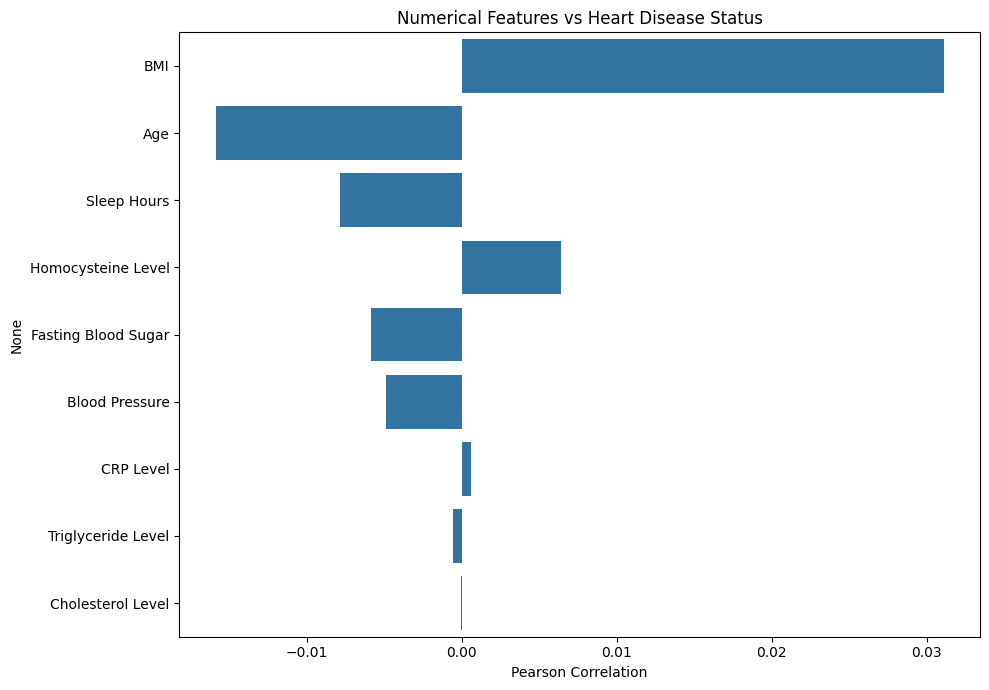


CATEGORICAL FEATURE RELATIONSHIPS:

Gender:
Heart Disease Status     0     1
Gender                          
Female                0.79  0.21
Male                  0.81  0.19

Exercise Habits:
Heart Disease Status      0      1
Exercise Habits                   
High                  0.803  0.197
Low                   0.801  0.199
Medium                0.796  0.204

Smoking:
Heart Disease Status      0      1
Smoking                           
No                    0.804  0.196
Yes                   0.797  0.203

Family Heart Disease:
Heart Disease Status      0      1
Family Heart Disease              
No                    0.798  0.202
Yes                   0.802  0.198

Diabetes:
Heart Disease Status    0    1
Diabetes                      
No                    0.8  0.2
Yes                   0.8  0.2

High Blood Pressure:
Heart Disease Status      0      1
High Blood Pressure               
No                    0.799  0.201
Yes                   0.801  0.199

Low HDL Cholesterol

In [80]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("=" * 65)
print("FEATURE-TARGET RELATIONSHIP ANALYSIS")
print("=" * 65)

# Use training data
analysis_df = X_train.copy()
analysis_df['Heart Disease Status'] = y_train

# Define feature types
numerical_features = analysis_df.drop(
    columns=['Heart Disease Status']
).select_dtypes(include=np.number).columns.tolist()

categorical_features = analysis_df.drop(
    columns=['Heart Disease Status']
).select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

# Target distribution
print("\nTARGET DISTRIBUTION:")
print(analysis_df['Heart Disease Status'].value_counts())

# Numerical feature correlations
numeric_cols = [
    col for col in numerical_features
    if col in analysis_df.columns
]

correlations = analysis_df[
    numeric_cols + ['Heart Disease Status']
].corr(numeric_only=True)['Heart Disease Status'].drop(
    'Heart Disease Status'
).sort_values(key=abs, ascending=False)

print("\nNUMERICAL FEATURE CORRELATIONS:")
print(correlations)

# Visualize numerical correlations
plt.figure(figsize=(10, 7))
sns.barplot(
    x=correlations.values,
    y=correlations.index
)
plt.title("Numerical Features vs Heart Disease Status")
plt.xlabel("Pearson Correlation")
plt.tight_layout()
plt.show()

# Categorical feature relationships
print("\nCATEGORICAL FEATURE RELATIONSHIPS:")

for col in categorical_features:
    print(f"\n{col}:")
    print(pd.crosstab(
        analysis_df[col],
        analysis_df['Heart Disease Status'],
        normalize='index'
    ).round(3))

print("\nFEATURE-TARGET ANALYSIS COMPLETED!")


In [81]:

# FINAL MODEL SELECTION - PROVISIONAL

from sklearn.base import clone
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import roc_auc_score, accuracy_score
import joblib

# Use Logistic Regression pipeline
final_model = clone(
    balanced_models["Logistic Regression"]
)

# Train on the complete training dataset
final_model.fit(X_train, y_train)

# Evaluate on untouched test dataset
y_final_pred = final_model.predict(X_test)
y_final_prob = final_model.predict_proba(X_test)[:, 1]

print("FINAL MODEL: LOGISTIC REGRESSION")
print("--------------------------------")

print("Accuracy:", accuracy_score(y_test, y_final_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_final_prob))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_final_pred,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_final_pred))

# Save complete preprocessing + model pipeline
joblib.dump(
    final_model,
    "heart_disease_model.pkl"
)

print("\nModel saved successfully!")


FINAL MODEL: LOGISTIC REGRESSION
--------------------------------
Accuracy: 0.504
ROC-AUC: 0.4836953125

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.52      0.62      1600
           1       0.19      0.46      0.27       400

    accuracy                           0.50      2000
   macro avg       0.49      0.49      0.45      2000
weighted avg       0.67      0.50      0.55      2000


Confusion Matrix:
[[825 775]
 [217 183]]

Model saved successfully!


In [82]:
rf_model = balanced_models["Random Forest"]

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred))
print("\nROC-AUC:", roc_auc_score(y_test, rf_prob))
print("\nClassification Report:")
print(classification_report(y_test, rf_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

Random Forest Accuracy: 0.8

ROC-AUC: 0.47309609375

Classification Report:
              precision    recall  f1-score   support

           0       0.80      1.00      0.89      1600
           1       0.00      0.00      0.00       400

    accuracy                           0.80      2000
   macro avg       0.40      0.50      0.44      2000
weighted avg       0.64      0.80      0.71      2000


Confusion Matrix:
[[1600    0]
 [ 400    0]]


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [83]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone

rf_pipeline = clone(preprocessor)

from sklearn.pipeline import Pipeline

rf_tuning_pipeline = Pipeline([
    ("preprocessor", rf_pipeline),
    ("classifier", RandomForestClassifier(
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

param_grid = {
    "classifier__n_estimators": [200, 300, 500],
    "classifier__max_depth": [5, 10, 15, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [2, 5, 10],
    "classifier__max_features": ["sqrt", 0.5]
}

search = RandomizedSearchCV(
    rf_tuning_pipeline,
    param_distributions=param_grid,
    n_iter=15,
    scoring="roc_auc",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print("Best CV ROC-AUC:", search.best_score_)

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best parameters: {'classifier__n_estimators': 300, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 5, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 10}
Best CV ROC-AUC: 0.5140091047174538


In [84]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

best_rf = search.best_estimator_

y_pred = best_rf.predict(X_test)
y_prob = best_rf.predict_proba(X_test)[:, 1]

print("TUNED RANDOM FOREST RESULTS")
print("---------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

TUNED RANDOM FOREST RESULTS
---------------------------
Accuracy: 0.7745
ROC-AUC: 0.4817125

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.96      0.87      1600
           1       0.16      0.03      0.05       400

    accuracy                           0.77      2000
   macro avg       0.48      0.50      0.46      2000
weighted avg       0.67      0.77      0.71      2000


Confusion Matrix:
[[1537   63]
 [ 388   12]]


In [85]:
import joblib

final_model = best_rf

joblib.dump(
    final_model,
    "heart_disease_model.pkl"
)

print("Tuned Random Forest saved successfully!")
print("Best parameters:")
print(search.best_params_)

Tuned Random Forest saved successfully!
Best parameters:
{'classifier__n_estimators': 300, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 5, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 10}


In [86]:
import json

feature_info = {}

for col in X.columns:
    if col in categorical_features:
        feature_info[col] = sorted(
            X[col].dropna().astype(str).unique().tolist()
        )
    else:
        feature_info[col] = "numeric"

print(json.dumps(feature_info, indent=4))

{
    "Age": "numeric",
    "Gender": [
        "Female",
        "Male"
    ],
    "Blood Pressure": "numeric",
    "Cholesterol Level": "numeric",
    "Exercise Habits": [
        "High",
        "Low",
        "Medium"
    ],
    "Smoking": [
        "No",
        "Yes"
    ],
    "Family Heart Disease": [
        "No",
        "Yes"
    ],
    "Diabetes": [
        "No",
        "Yes"
    ],
    "BMI": "numeric",
    "High Blood Pressure": [
        "No",
        "Yes"
    ],
    "Low HDL Cholesterol": [
        "No",
        "Yes"
    ],
    "High LDL Cholesterol": [
        "No",
        "Yes"
    ],
    "Alcohol Consumption": [
        "High",
        "Low",
        "Medium",
        "Unknown"
    ],
    "Stress Level": [
        "High",
        "Low",
        "Medium"
    ],
    "Sleep Hours": "numeric",
    "Sugar Consumption": [
        "High",
        "Low",
        "Medium"
    ],
    "Triglyceride Level": "numeric",
    "Fasting Blood Sugar": "numeric",
    "CRP Level": "n

In [87]:
import json
import joblib

# Save tuned Random Forest
joblib.dump(final_model, "heart_disease_model.pkl")

# Create input configuration
feature_config = {}

for col in X.columns:
    if col in categorical_features:
        feature_config[col] = {
            "type": "categorical",
            "options": sorted(X[col].dropna().astype(str).unique().tolist())
        }
    else:
        feature_config[col] = {
            "type": "numeric",
            "default": float(X[col].median()),
            "min": float(X[col].min()),
            "max": float(X[col].max())
        }

with open("feature_config.json", "w") as f:
    json.dump(feature_config, f, indent=4)

print("Model and feature configuration saved!")

Model and feature configuration saved!


In [88]:

app_code = r'''
import streamlit as st
import pandas as pd
import joblib
import json

st.set_page_config(
    page_title="Heart Disease ML Project",
    page_icon="❤️",
    layout="wide"
)

@st.cache_resource
def load_model():
    return joblib.load("heart_disease_model.pkl")

@st.cache_data
def load_config():
    with open("feature_config.json", "r") as f:
        return json.load(f)

model = load_model()
config = load_config()

st.title("❤️ Heart Disease Prediction")
st.caption("Machine Learning Demonstration | Random Forest")

st.warning(
    "Educational demonstration only. This experimental model "
    "is not intended for medical diagnosis or treatment. "
    "Do not use its output to make health decisions."
)

st.markdown(
    "Enter the dataset features below to see how the trained "
    "machine-learning model classifies the supplied data."
)

with st.form("prediction_form"):
    st.subheader("Enter Feature Details")

    user_input = {}

    columns = st.columns(2)

    for index, (feature, details) in enumerate(config.items()):
        with columns[index % 2]:
            if details["type"] == "numeric":
                user_input[feature] = st.number_input(
                    feature,
                    min_value=float(details["min"]),
                    max_value=float(details["max"]),
                    value=float(details["default"]),
                    step=0.1,
                    key=feature
                )
            else:
                user_input[feature] = st.selectbox(
                    feature,
                    details["options"],
                    key=feature
                )

    submitted = st.form_submit_button(
        "Run ML Prediction",
        use_container_width=True
    )

if submitted:
    input_df = pd.DataFrame([user_input])

    prediction = int(model.predict(input_df)[0])
    scores = model.predict_proba(input_df)[0]

    st.divider()
    st.subheader("Model Output")

    if prediction == 1:
        st.error("Model class output: Yes (Class 1)")
    else:
        st.success("Model class output: No (Class 0)")

    st.write(
        "This is the model's classification, not a medical assessment."
    )

    st.subheader("Model Scores")

    score_df = pd.DataFrame({
        "Class": ["No (0)", "Yes (1)"],
        "Model score": scores
    })

    st.bar_chart(
        score_df.set_index("Class")
    )

    st.caption(
        "Scores are classifier outputs and are not validated "
        "medical probabilities or estimates of individual health risk."
    )

    with st.expander("View submitted input"):
        st.dataframe(input_df, use_container_width=True)

st.divider()
st.caption("Academic Machine Learning Project | Random Forest Classifier")
'''

with open("app.py", "w") as f:
    f.write(app_code)

requirements = """
streamlit
pandas
scikit-learn
joblib
"""

with open("requirements.txt", "w") as f:
    f.write(requirements.strip())

print("app.py created successfully!")
print("requirements.txt created successfully!")


app.py created successfully!
requirements.txt created successfully!


In [89]:
import os

files = [
    "app.py",
    "requirements.txt",
    "feature_config.json",
    "heart_disease_model.pkl"
]

for file in files:
    status = "✅ Available" if os.path.exists(file) else "❌ Missing"
    print(f"{file}: {status}")

app.py: ✅ Available
requirements.txt: ✅ Available
feature_config.json: ✅ Available
heart_disease_model.pkl: ✅ Available


In [90]:
from google.colab import files

project_files = [
    "app.py",
    "requirements.txt",
    "feature_config.json",
    "heart_disease_model.pkl"
]

for file in project_files:
    files.download(file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [91]:
import sklearn
import numpy
import joblib
import sys

print("Python:", sys.version)
print("Scikit-learn:", sklearn.__version__)
print("NumPy:", numpy.__version__)
print("Joblib:", joblib.__version__)

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Scikit-learn: 1.6.1
NumPy: 2.4.6
Joblib: 1.6.0
